In [1]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util
from glob import glob
import seaborn as sns
import imageio
import tempfile
import pandas as pd
from metpy.calc import wind_direction, wind_speed
from metpy.units import units
from tracemalloc import start
from math import gamma

import numpy as np
import xarray as xr
from netCDF4 import Dataset
import iris

from scipy.special import gamma
from scipy.special import gammainc, gammaincc, gdtr

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

sys.path.append('/home/users/esree/dcmex_instruments/faam_data/')
# loads of homemade functions <3 <3
from faam_data_functions import faam_mo_files, time_adjust, get_nc_variable, mask_data, flatten_20hz_variable, mo_mean, datetime_to_sec, cloud_pass_time
from faam_data_functions_v2 import faam_mo_files_v2, make_cdp_psd_v2, make_cdp_conc

sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz, ztp, drag

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


# specifically pulling out values for cloud drop distribution

In [2]:
faam_mo_paths_dic = faam_mo_files_v2() # dictionary containing dates + paths to nc files
date = '220730'
date_dict = faam_mo_paths_dic[date]
core_phys_pth = date_dict['cloud_physics_1hz']
faam_pth = date_dict['faam_core']
faam_pth_high = date_dict['faam_core_high']
mo_path = date_dict['mo_non_core_1hz']
mo_path_64hz = date_dict['mo_non_core']

In [3]:
### cloud droplet concentration #######################################
cdp_psd = make_cdp_psd_v2(date_dict, file_name = 'cloud_physics') # this has no averaging
cdp_conc = make_cdp_conc(date_dict, file_name = 'cloud_physics') # this has no averaging

## faam alt + temp + tas + w - this is default 1hz, cba to change to higher one
alt_unit, alt_longname, alt = get_nc_variable(faam_pth_high, 'ALT_GIN')
alt = alt.rename({'Time': 'time'})
alt_high_flat, alt_time_high = flatten_20hz_variable(alt)


tas_unit, tas_longname, tas = get_nc_variable(faam_pth, 'TAS_RVSM')
tas = tas.rename({'Time': 'time'})

faam_w_unit_high, faam_w_longname_high, faam_w_high = get_nc_variable(faam_pth_high, 'W_C')
faam_w_high = faam_w_high.rename({'Time': 'time'})
w_high_flat, w_time_high = flatten_20hz_variable(faam_w_high)

tas_unit_high, tas_longname_high, tas_high = get_nc_variable(faam_pth_high, 'TAS_RVSM')
tas_high = tas_high.rename({'Time': 'time'})
tas_flat, tas_time_high = flatten_20hz_variable(tas_high)

LWC_unit, LWC_longname, LWC = mo_mean(mo_path, ('LWC1','LWC2'))

LWC_unit_64hz, LWC_longname_64hz, LWC_64hz = mo_mean(mo_path_64hz, ('LWC1','LWC2'))


In [4]:
combined_dic = {
    'w_faam_high': {'data': w_high_flat, 'unit': faam_w_unit_high, 'time': w_time_high, 'colour': 'coral', 'label' : 'W faam 32hz'},
    'alt_gin': {'data': alt_high_flat, 'unit': alt_unit, 'time': alt_time_high, 'colour': 'tab:red', 'label' : 'Alt'},
    'mean_LWC': {'data': LWC, 'unit': LWC_unit, 'time': LWC['Time'].values, 'colour': 'crimson', 'label' : 'LWC 1hz'},
    'mean_LWC_64hz': {'data': LWC_64hz, 'unit': LWC_unit_64hz, 'time': LWC_64hz['Time'].values, 'colour': 'purple', 'label' : 'LWC 64hz'},
    'tas': {'data': tas, 'unit': tas_unit, 'time': tas['time'].values, 'colour': 'orange', 'label' : 'TAS'},
    'tas_high': {'data': tas_flat, 'unit': tas_unit_high, 'time': tas_time_high, 'colour': 'darkorange', 'label' : 'TAS 32hz'},
    'cdp_psd': {'data': cdp_psd, 'unit': cdp_psd.attrs.get('units'), 'time': cdp_psd['time'].values, 'colour': 'black', 'label' : 'CDP PSD'},
    'cdp_conc': {'data': cdp_conc, 'unit': cdp_conc.attrs.get('units'), 'time': cdp_conc['time'].values, 'colour': 'black', 'label' : 'CDP Conc'}}

In [ ]:
LWC_g = combined_dic['mean_LWC_64hz']['data']
LWC_kg = LWC_g/1000 # convert to kg/m3
# remove zero values
# Compute the boolean mask
mask = (LWC_g > 1).compute()

# Remove zero and negative values
LWC_nonzero = LWC_kg.where(mask, drop=True)

mean = LWC_nonzero.mean().values
std_dev = LWC_nonzero.std().values
max_value = LWC_nonzero.max().values
min_value = LWC_nonzero.min().values

## current distributions

### gaussian

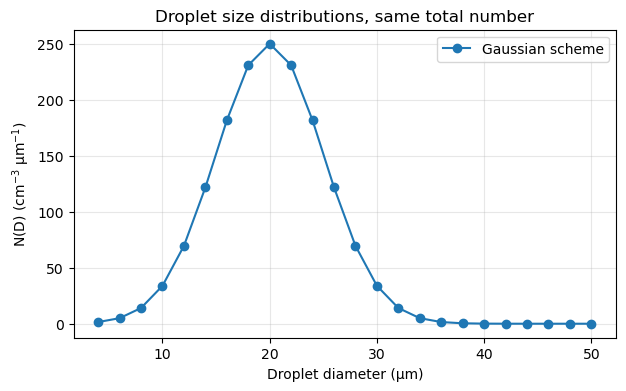

In [ ]:

# ---------- Your Gaussian scheme ----------
DIS, dbar, NMAX = 0.25, 20, 500.e6
stdv = DIS * dbar / 2.

k = np.arange(24)
xi = 26. - (k + 1.)                                   # channel radius (µm)
yi = NMAX * np.exp(-((xi - dbar / 2.) / stdv) ** 2 / 2.)   # m^-3 per channel

D_gauss = 2 * xi * 1e-6                               # channel diameter (m)
dD = 2e-6                                             # channel width in diameter (m)
n_gauss = yi / dD                                     # size density (m^-3 m^-1)


# ---------- Plot (m^-3 m^-1  ->  cm^-3 µm^-1) ----------
conv = 1e-12
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(D_gauss * 1e6, n_gauss * conv, "o-", label="Gaussian scheme")
ax.set_xlabel("Droplet diameter (µm)")
ax.set_ylabel("N(D) (cm$^{-3}$ µm$^{-1}$)")
ax.set_title("Droplet size distributions, same total number")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [7]:
# make up some numbers
'''
pos = 600 # 6000m alt
rad = .5 * 1.0e-3 # in m
dmm = rad * 2.0e3
GRAV = 9.81 # gravity
RD = 287.05 # gas constant for dry air (J/kg/K)
temp = tr[pos] - 1.
pres = ps[pos] * 100.
rhoa = pres / (RD * temp)
rhog = 900. # initial ice density (kg m^-3)
cd = drag(rad, rhog, rhoa)
# initial mass
mass = 4. * np.pi * rad ** 3 * rhog / 3.
ts = 268.15
vt = 8. * rad * rhog * GRAV / (3. * rhoa * cd)
vt = vt ** 0.5
'''


k = 2
DBAR = 20. # mean diameter (µm)
DIS = 0.25 # dispersion 
stdv = DIS * DBAR / 2.
NMAX = 500.e6
dbar = 30

xi = (26. - (k + 1.)) * 1.0e-6 # this is size (m)

hxa = (xi * 1.0e6 - dbar / 2.) / stdv
hxa = hxa ** 2 / 2.
yi = NMAX * math.exp(-hxa)

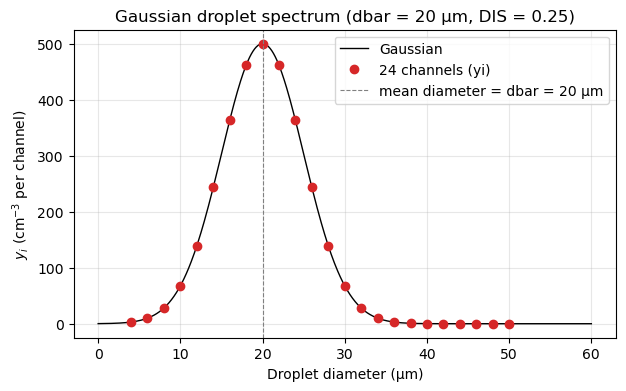

In [13]:
import math
import numpy as np
import matplotlib.pyplot as plt

DIS, NMAX, dbar = 0.25, 500.e6, 20
stdv = DIS * dbar / 2.                      # std dev in radius (µm)

# continuous curve, x = droplet diameter (µm)
D = np.linspace(0, 60, 600)
curve = NMAX * np.exp(-((D / 2. - dbar / 2.) / stdv) ** 2 / 2.)

# the 24 channel values, calculated as in your loop
D_k, y_k = [], []
for k in range(24):
    xi = (26. - (k + 1.)) * 1.0e-6          # radius (m)
    hxa = (xi * 1.0e6 - dbar / 2.) / stdv
    hxa = hxa ** 2 / 2.
    yi = NMAX * math.exp(-hxa)
    D_k.append(2 * xi * 1.0e6)              # diameter (µm)
    y_k.append(yi)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(D, curve / 1e6, 'k', lw=1, label='Gaussian')
ax.plot(D_k, np.array(y_k) / 1e6, 'o', color='C3', label='24 channels (yi)')
ax.axvline(dbar, color='grey', ls='--', lw=0.8, label=f'mean diameter = dbar = {dbar} µm')
ax.set_xlabel('Droplet diameter (µm)')
ax.set_ylabel(r'$y_i$ (cm$^{-3}$ per channel)')
ax.set_title(f'Gaussian droplet spectrum (dbar = {dbar} µm, DIS = {DIS})')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### casim

In [ ]:
### Function for model gamma function in (m-3 m-1)
# x = diameter, n = number conc, mu = mu, lambda = lambda (needs calculating)
def model_gamma_pdf(x,n,mu,lamda):
    n0 = (n) * (lamda**(1+mu)) / (gamma(1+mu)) # directly pulled from field paper - (A2)
    N = n0 * (x**mu) * (np.exp(-lamda*x)) 
    return N

### Function for using scipy.special.gdtr to calculate the gamma distribution cumulative distribution function
### I don't like this because in the gdtr you have to switch the order of mu and lambda :(
def model_gamma_cdf(x,n,mu,lam):
    return n*gdtr(lam,1+mu,x)

### Function for integral over the lower and upper limits of the gamma PDF
def partial_integral_gamma(n,mu,lam,lower,upper):
    lower_inc = gammainc(1+mu,lam*lower)
    upper_inc = gammainc(1+mu,lam*upper)
    return n*(upper_inc-lower_inc)

## Function for calculating lamda from mass and number
## with prescribed model number + mass (+ specify type of hydrometeor), lambda can be calculated - to work out distribution
def calc_lambda(model_mass,model_num,hydro):
    # Read in gamma PDF values (Field et al., 2023, Table 1)
    mu = hydroparameters[hydro][0]
    c = hydroparameters[hydro][1]
    d = hydroparameters[hydro][2]
    
    gamma_ratio = gamma(1+mu+d) / gamma(1+mu)
    nm_ratio = model_num / model_mass
    if d == 2:
        lam = np.sqrt(c*nm_ratio*gamma_ratio)
    elif d == 3:
        lam = np.cbrt(c*nm_ratio*gamma_ratio)
    else:
        print("Woohoo, something is wrong here for the moment value!")
        lam = np.nan
    return lam


### Ditionary contains mu, mass-dimention (a,b)
hydroparameters = {'liquid':[2.5,522,3],
                   'rain':[2.5,522,3],
                   'ice':[2.5,np.pi*200/6,3],
                   'snow':[2,0.026,2],
                   'graupel':[2.5,np.pi*500/6,3]}

mu: 2.5 
total conc: 150.0 cm-3 
LWC: 0.6 g/m3


(0.0, 26.0)

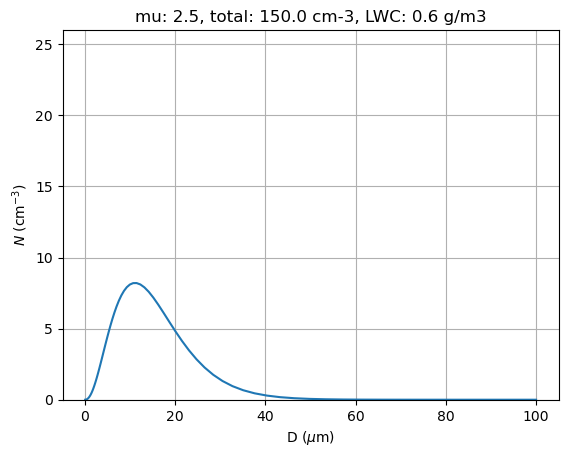

In [ ]:
hydro='liquid'
n = 150e6 # m-3 # total cloud drop conc
m = 0.0003 *2#0.0013 # # kg m-3 - prescribed LWC
mu = hydroparameters[hydro][0] # 4
lam = calc_lambda(m,n,hydro)
#print(f'mu: {mu} \nlambda: {lam} \n(n conc = {n/1e6}) cm-3, LWC = {m*1000} g/m3')
print(f'mu: {mu} \ntotal conc: {n/1e6} cm-3 \nLWC: {m*1000} g/m3')

fig = plt.figure()
ax1 = fig.add_subplot(111)
#ax2 = ax1.twinx()

powers = np.linspace(-7,-4,100)
bins   = 10**powers

#ax1.plot(bins*1e6, model_gamma_pdf(bins,n,mu,lam)/1e6)
ax1.plot(bins*1e6, model_gamma_pdf(bins,n,mu,lam)/1e12)
ax1.grid(True)
'''
ax2.plot(bins*1e6,
         model_gamma_cdf(bins,n,mu,lam)/1e6,
         color='k')

## Just to check that they are the same
ax2.scatter(5,n*gammainc(1+mu,lam*5e-6)/1e6)
ax2.scatter(5,model_gamma_cdf(5e-6,n,mu,lam)/1e6,
            marker='s',facecolor='none',edgecolor='C0',
            s=90)

ax2.scatter(50,n*gammainc(1+mu,lam*50e-6)/1e6)
ax2.scatter(50,model_gamma_cdf(50e-6,n,mu,lam)/1e6,
            marker='s',facecolor='none',edgecolor='C1',
            s=90)
'''
# doing it both ways to show it is the same
'''
print(partial_integral_gamma(n,mu,lam,5e-6,50e-6)/1e6) # total number conc per cm-3
print((model_gamma_cdf(50e-6,n,mu,lam) - model_gamma_cdf(5e-6,n,mu,lam))/1e6)
print(partial_integral_gamma(n, mu, lam, 0, np.inf) / 1e6)   # should print n
'''

ax1.set_ylabel('$N$ (cm$^\mathrm{-3}$)')
ax1.set_xlabel('D ($\mu$m)')
# ax1.set_yscale('log')
#ax1.set_xscale('log')
ax1.set_title(f'mu: {mu}, total: {n/1e6} cm-3, LWC: {m*1000} g/m3')
ax1.set_ylim(0, 26)

In [ ]:
def casim_channels(n, m, hydro='liquid', lump_tails=True):
    """Number concentration (m^-3) in each of the 24 channels.
    n: total number (m^-3), m: mass concentration (kg m^-3)
    Index k matches your loop: k=0 is the largest channel, k=23 the smallest."""
    mu = hydroparameters[hydro][0]
    lam = calc_lambda(m, n, hydro)                 # m^-1

    k = np.arange(24)
    D_c = 2. * (25. - k) * 1.0e-6                  # channel centre diameter (m): 50 -> 4 µm
    lo = D_c - 1.0e-6                              # edges: ±1 µm in diameter
    hi = D_c + 1.0e-6
    if lump_tails:
        lo[-1] = 0.                                # k=23 takes everything below its upper edge
        hi[0] = np.inf                             # k=0 takes everything above its lower edge
    return partial_integral_gamma(n, mu, lam, lo, hi)

yi_all = casim_channels(n, m)          # n, m from the model state, in SI units

"""
## use in the model
yi_all = casim_channels(n, m)          # n, m from the model state, in SI units

for k in range(24):
    yi = yi_all[k]                     # replaces xi / hxa / yi = NMAX * math.exp(-hxa)
    sumy = yi + sumy
    # ... kappa block and sumkap unchanged ...
"""

'\n## use in the model\nyi_all = casim_channels(n, m)          # n, m from the model state, in SI units\n\nfor k in range(24):\n    yi = yi_all[k]                     # replaces xi / hxa / yi = NMAX * math.exp(-hxa)\n    sumy = yi + sumy\n    # ... kappa block and sumkap unchanged ...\n'

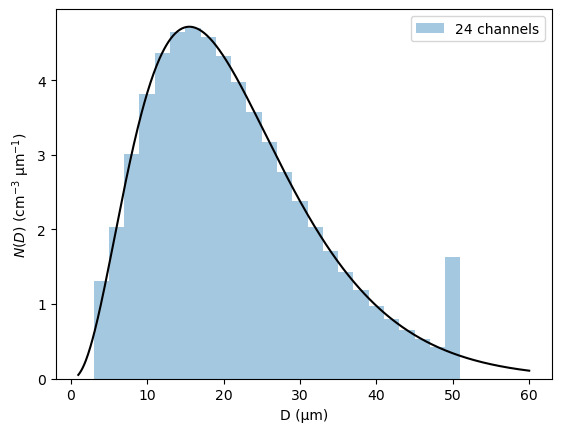

In [ ]:
Dc_um = 2 * (25. - np.arange(24))
plt.bar(Dc_um, yi_all / 2e-6 / 1e12, width=2, alpha=0.4, label='24 channels')   # cm^-3 µm^-1
Dm = np.linspace(1e-6, 60e-6, 600)
plt.plot(Dm * 1e6, model_gamma_pdf(Dm, n, mu, calc_lambda(m, n, 'liquid')) / 1e12, 'k')
plt.xlabel('D (µm)'); plt.ylabel(r'$N(D)$ (cm$^{-3}$ µm$^{-1}$)'); plt.legend()

number in channels: lumped 1.000, truncated 0.979 of n


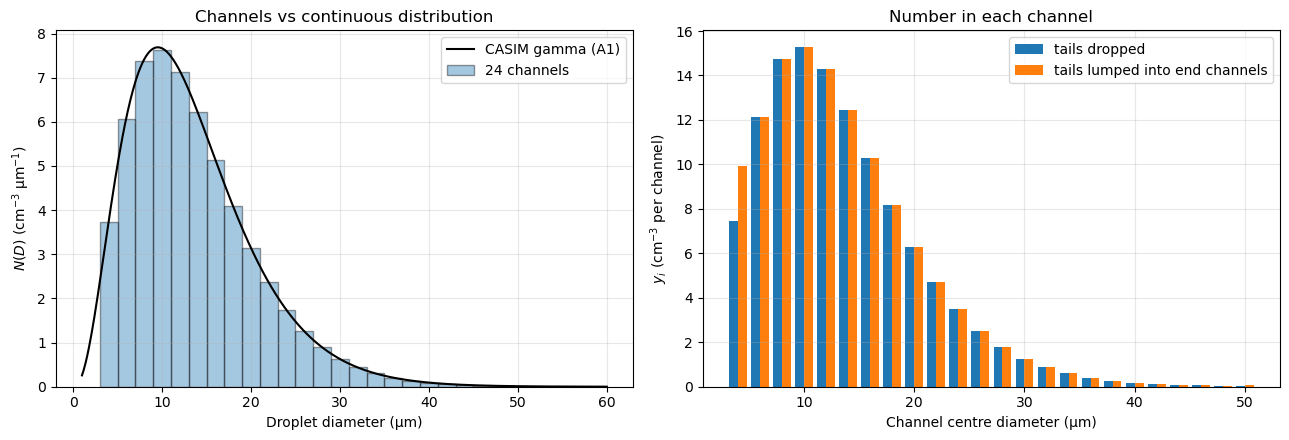

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- inputs (SI units) ----
n, m, hydro = 120e6, 3e-4, 'liquid'      # m^-3, kg m^-3
mu = hydroparameters[hydro][0]
lam = calc_lambda(m, n, hydro)           # m^-1

yi_lump  = casim_channels(n, m, hydro, lump_tails=True)    # m^-3 per channel
yi_trunc = casim_channels(n, m, hydro, lump_tails=False)

k = np.arange(24)
D_c = 2. * (25. - k)                     # channel centre diameter (µm): 50 -> 4
width = 2.                               # channel width (µm)

print(f"number in channels: lumped {yi_lump.sum()/n:.3f}, truncated {yi_trunc.sum()/n:.3f} of n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# ---- left: channels vs continuous curve, as a size density (cm^-3 µm^-1) ----
Dm = np.linspace(1e-6, 60e-6, 600)                       # m
ax1.plot(Dm * 1e6, model_gamma_pdf(Dm, n, mu, lam) / 1e12, 'k', label='CASIM gamma (A1)')
ax1.bar(D_c, yi_trunc / (width * 1e-6) / 1e12, width=width,
        alpha=0.4, edgecolor='k', label='24 channels')
ax1.set_xlabel('Droplet diameter (µm)')
ax1.set_ylabel(r'$N(D)$ (cm$^{-3}$ µm$^{-1}$)')
ax1.set_title('Channels vs continuous distribution')
ax1.legend()
ax1.grid(alpha=0.3)

# ---- right: number per channel (cm^-3), tails dropped vs lumped ----
ax2.bar(D_c - 0.4, yi_trunc / 1e6, width=0.8, label='tails dropped')
ax2.bar(D_c + 0.4, yi_lump / 1e6, width=0.8, label='tails lumped into end channels')
ax2.set_xlabel('Channel centre diameter (µm)')
ax2.set_ylabel(r'$y_i$ (cm$^{-3}$ per channel)')
ax2.set_title('Number in each channel')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## observation distributions

In [ ]:
start_times_buf, end_times_buf = cloud_pass_time(mo_path_64hz, sec_buffer=5)


cloud pass 16:47:34 to 16:47:44
cloud pass 16:49:32 to 16:49:42


KeyboardInterrupt: 

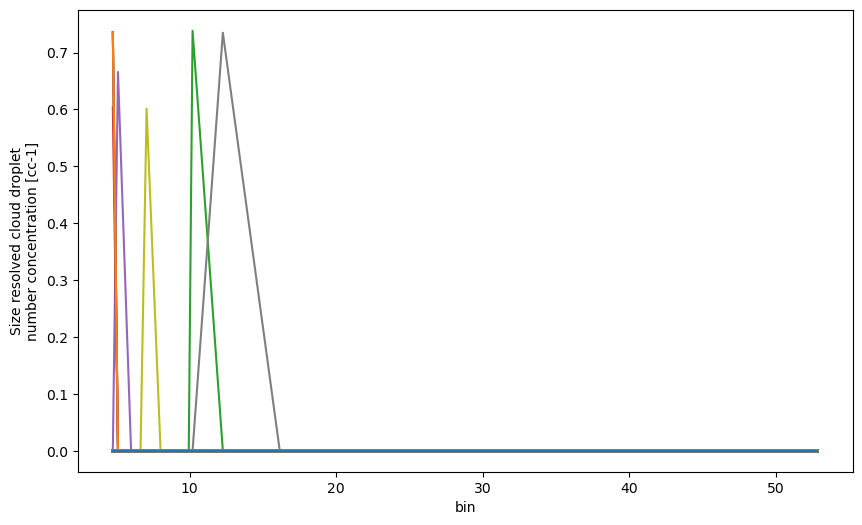

<Figure size 1000x600 with 0 Axes>

In [ ]:
for i, (dt_start, dt_end) in enumerate(zip(start_times_buf, end_times_buf)):
    sliced_dic = {}
    pass_title = (f'cloud pass {str(dt_start)[11:]} to {str(dt_end)[11:]}')

    sliced_dic = {}
    for var, d in combined_dic.items():
        time = pd.to_datetime(d["time"])
        mask = (time >= dt_start) & (time <= dt_end)

        if hasattr(d["data"], "sel"):
            time_coord = "time" if "time" in d["data"].coords else "Time"
            sliced_data = d["data"].sel({
                time_coord: slice(dt_start, dt_end)
            })     

        else:
            # this is the cnn data, need to split into habits
            sliced_data = d["data"][mask]
            
        sliced_dic[var] = {
            **d,
            "data": sliced_data,
            "time": time[mask],
        }
    print(pass_title)
    plt.figure(figsize=(10, 6))
    #plt.plot(sliced_dic['cdp_conc']['time'], sliced_dic['cdp_conc']['data'], color='black', label='CDP Conc')
    sliced_dic['cdp_psd']['data'].plot(x='bin', hue='time', add_legend=False)



In [ ]:
## i think there is a lot of noise. need to filter out where 
combined_dic['cdp_conc']['data']

#mean = combined_dic['cdp_conc']['data'].nanmean(dim='time')
da = combined_dic['cdp_conc']['data']
da_masked = da.where(da > 0)  # Mask out non-positive values
mean = da_masked.mean(dim='time', skipna=True)
sd = da_masked.std(dim='time', skipna=True)

In [ ]:
mean.values

array(155.98352, dtype=float32)

In [ ]:
sd.values

array(146.11551, dtype=float32)

In [ ]:
a_time_idx = 8
dt_start = start_times_buf[a_time_idx]
dt_end = end_times_buf[a_time_idx]
pass_title = (f'cloud pass {str(dt_start)[11:]} to {str(dt_end)[11:]}')

sliced_dic = {}
for var, d in combined_dic.items():
    time = pd.to_datetime(d["time"])
    mask = (time >= dt_start) & (time <= dt_end)

    if hasattr(d["data"], "sel"):
        time_coord = "time" if "time" in d["data"].coords else "Time"
        sliced_data = d["data"].sel({
            time_coord: slice(dt_start, dt_end)
        })     

    else:
        # this is the cnn data, need to split into habits
        sliced_data = d["data"][mask]
        
    sliced_dic[var] = {
        **d,
        "data": sliced_data,
        "time": time[mask],
    }

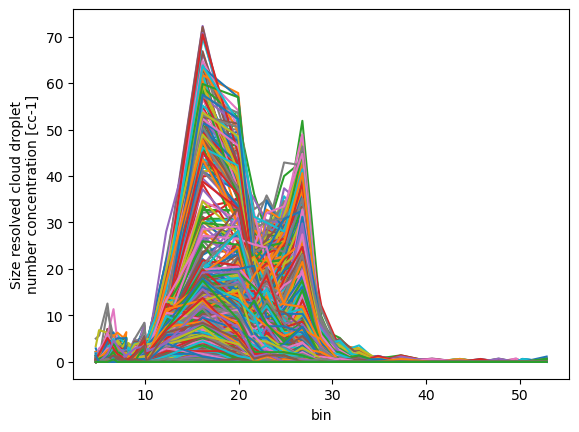

In [ ]:
masked_data = sliced_dic['cdp_psd']['data'].where(sliced_dic['cdp_conc']['data'] > 0)  # Mask out non-positive values

masked_data.plot(x='bin', hue='time', add_legend=False)

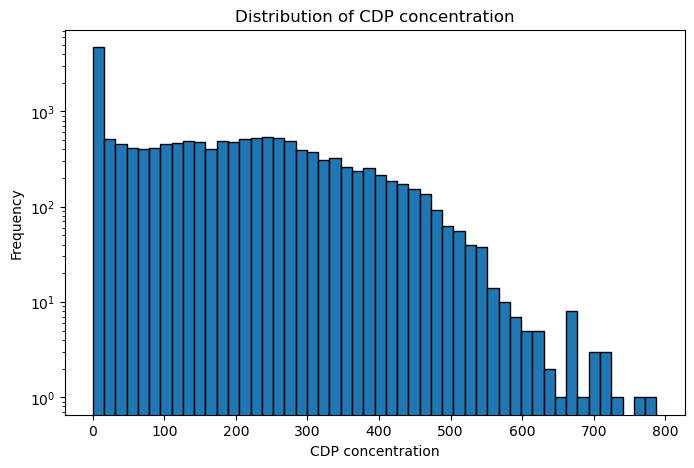

In [ ]:
da = combined_dic['cdp_conc']['data']
da_masked = da.where(da > 0)  # Mask out non-positive values
plt.figure(figsize=(8, 5))
plt.hist(da_masked.values.flatten(), bins=50, edgecolor='black')

plt.yscale('log')
plt.xlabel('CDP concentration')
plt.ylabel('Frequency')
plt.title('Distribution of CDP concentration')
plt.show()

### themal distribution

In [ ]:
## actually, mask out to get only thermal distribution
lwc_threshold = 0
w_threshold = 7 #[0, 2, 5, 7, 10]

w_faam_high = combined_dic['w_faam_high']['data']
w_faam_high_masked = w_faam_high.where(w_faam_high >= w_threshold)


lwc_data = combined_dic['mean_LWC_64hz']['data']
lwc_data = lwc_data.rename({'Time': 'time'})
lwc_aligned = lwc_data.interp(time=w_faam_high['time'])
lwc_masked = lwc_aligned.where(lwc_aligned >= lwc_threshold)

valid = w_faam_high_masked.notnull() & lwc_masked.notnull()


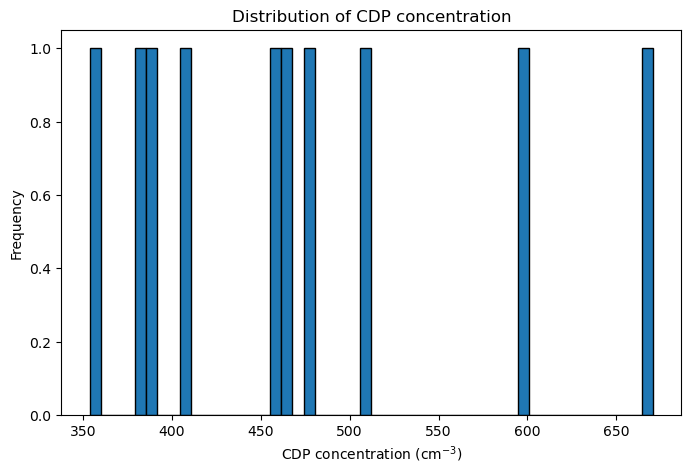

In [ ]:
da = combined_dic['cdp_conc']['data']
da_masked = da.where(valid)  # Mask out non-positive values
plt.figure(figsize=(8, 5))
plt.hist(da_masked.values.flatten(), bins=50, edgecolor='black')

#plt.yscale('log')
plt.xlabel('CDP concentration (cm$^{-3}$)')
plt.ylabel('Frequency')
plt.title('Distribution of CDP concentration')
plt.show()

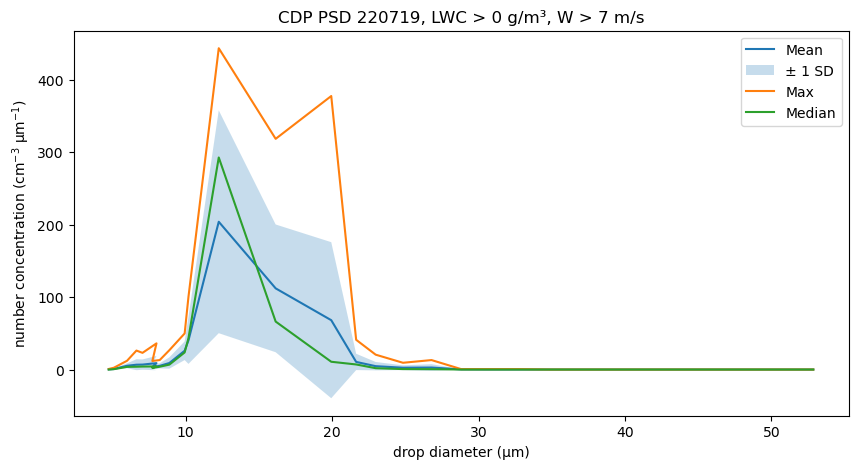

In [ ]:
masked_data = combined_dic['cdp_psd']['data'].where(valid)  # Mask out non-positive values

mean = masked_data.mean(dim='time')
sd = masked_data.std(dim='time')
maximum = masked_data.max(dim='time')
median = masked_data.median(dim='time')

#masked_data.plot(x='bin', hue='time', add_legend=False)
fig, ax = plt.subplots(figsize=(10, 5))

#for t in masked_data['time'].values:
#    ax.plot(
#        masked_data['bin'].values,
#        masked_data.sel(time=t).values)
x = masked_data['bin'].values
m = mean.values
s = sd.values

ax.plot(x, m, label='Mean')
ax.fill_between(x, m - s, m + s, alpha=0.25, label='± 1 SD')
ax.plot(x, maximum.values, label='Max')
ax.plot(x, median.values, label='Median')

ax.set_xlabel('drop diameter (µm)')
ax.set_ylabel('number concentration (cm$^{-3}$ µm$^{-1}$)')
ax.set_title(f'CDP PSD {date}, LWC > {lwc_threshold} g/m³, W > {w_threshold} m/s')
ax.legend()
plt.show()

In [ ]:
x

array([ 4.74386,  5.09491,  5.99102,  6.63637,  7.05031,  8.0045 ,
        7.72481,  8.22654,  8.8844 ,  9.92842, 10.1891 , 12.2573 ,
       16.1436 , 19.9391 , 21.6399 , 22.9714 , 24.8368 , 26.7869 ,
       28.8036 , 30.7853 , 32.8362 , 34.8568 , 37.2986 , 40.6258 ,
       43.5968 , 45.8004 , 47.7289 , 49.5881 , 50.2962 , 52.8561 ],
      dtype=float32)

### altitude distribution

Text(0, 0.5, 'Frequency')

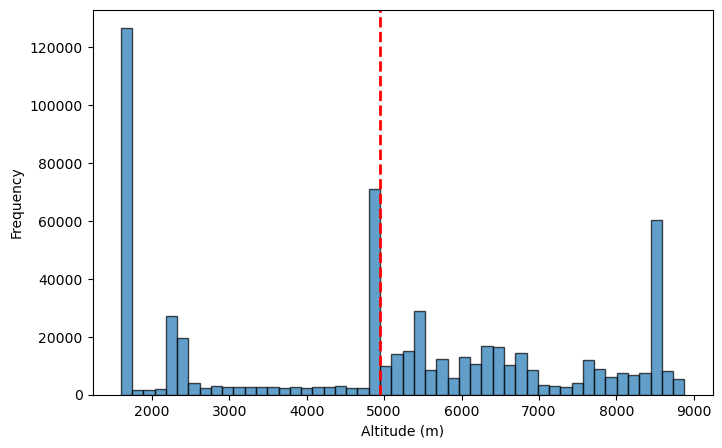

In [ ]:
alt_data =combined_dic['alt_gin']['data']
data = alt_data.values.flatten()
data = data[~np.isnan(data)]

mean = np.mean(data)
sd = np.std(data)

plt.figure(figsize=(8, 5))

plt.hist(data, bins=50, edgecolor='black', alpha=0.7)

plt.axvline(mean, color='red', linestyle='--',
            linewidth=2, label=f'Mean = {mean:.2f}')

plt.xlabel('Altitude (m)')
plt.ylabel('Frequency')

In [ ]:
min_alt = np.floor(alt_data.min(skipna=True).compute().item() / 100) * 100
max_alt = np.ceil(alt_data.max(skipna=True).compute().item() / 100) * 100

bin_edges = np.arange(min_alt, max_alt + 100, 500)

In [ ]:
## slice up the distributions according to altitude bins
## !! also need above 50cc conc (per second) to be included in the distribution
## this is not accounting for time!!
cdp_conc_data = combined_dic['cdp_conc']['data']
cdp_psd_data = combined_dic['cdp_psd']['data']

min_cdp_conc = 100  # minimum concentration threshold

alt_slice = {}
for i in range(len(bin_edges) - 1):
    lower_bound = bin_edges[i]
    upper_bound = bin_edges[i + 1]

    '''
    # Create a mask for the current altitude range
    alt_mask = (alt_data >= lower_bound) & (alt_data < upper_bound)

    # Apply the mask to the CDP concentration data
    cdp_conc_data = combined_dic['cdp_conc']['data']
    cdp_mask = cdp_conc_data.where(cdp_conc_data > 50)

    valid = alt_mask.notnull() & cdp_mask.notnull()
    masked_data = combined_dic['cdp_psd']['data'].where(valid)  # Mask out non-positive values

    # Store the masked data in the dictionary
    alt_slice[f"{lower_bound:.0f}-{upper_bound:.0f}"] = masked_data
    '''

    # Select observations within altitude range
    alt_mask = (
        (alt_data >= lower_bound) &
        (alt_data < upper_bound)
    )

    # Select observations where concentration > 50
    cdp_mask = cdp_conc_data > min_cdp_conc

    # Combine masks
    valid = alt_mask & cdp_mask

    # Apply combined mask to PSD
    masked_data = cdp_psd_data.where(valid)

    # Store
    alt_slice[f"{lower_bound:.0f}-{upper_bound:.0f}"] = masked_data



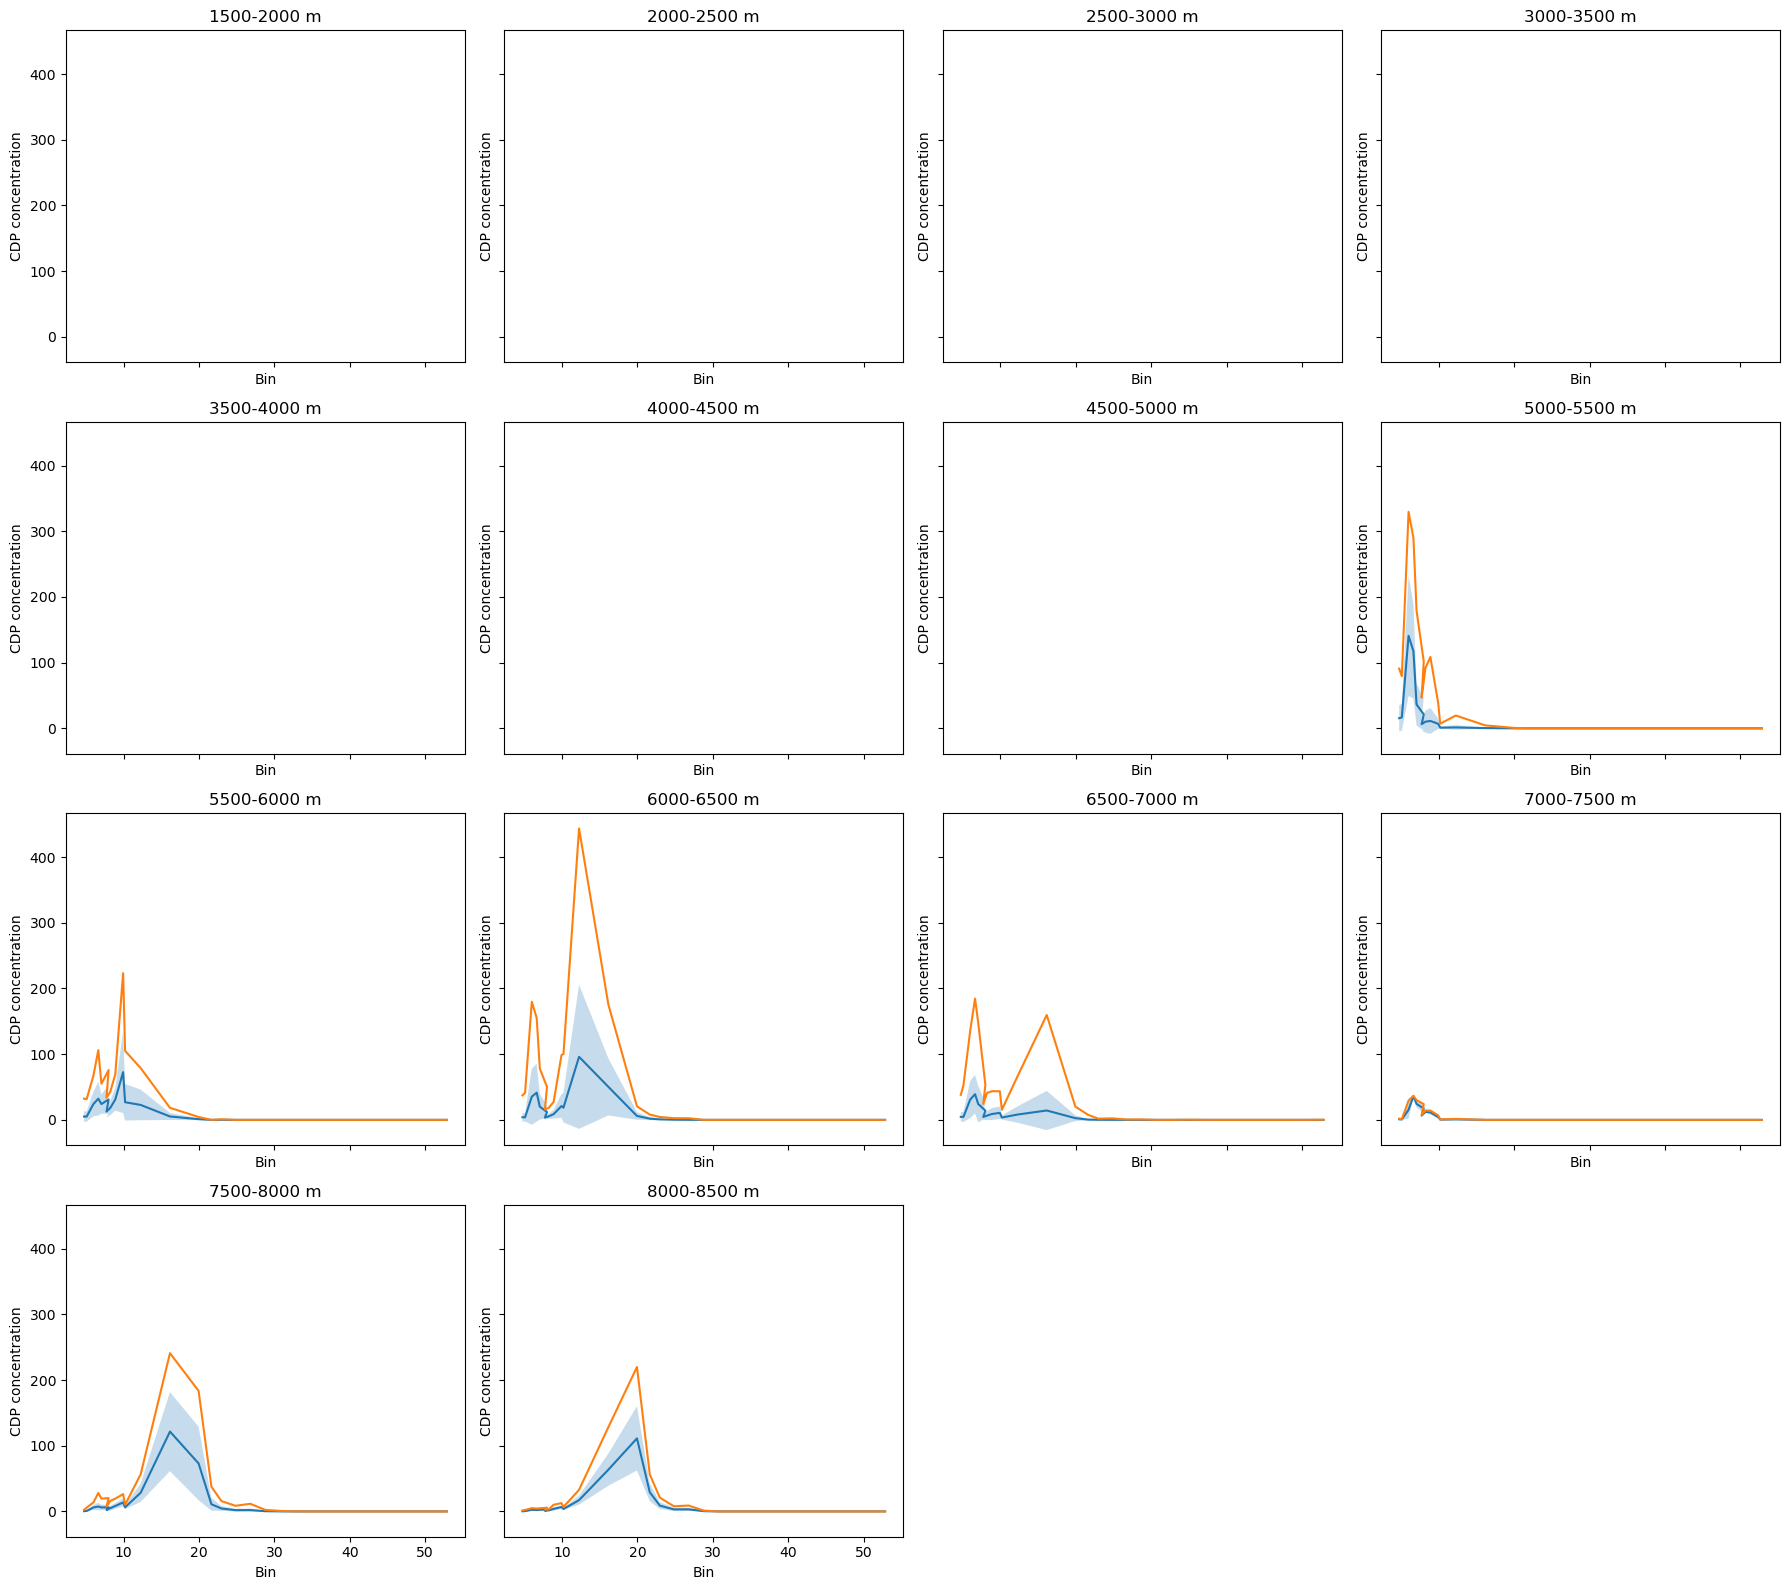

In [ ]:

altitude_keys = list(alt_slice.keys())

n = len(altitude_keys)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4 * nrows),
    sharex=True,
    sharey=True)

axes = axes.flatten()

for i, key in enumerate(altitude_keys):

    data = alt_slice[key]
    mean = data.mean(dim='time')
    sd = data.std(dim='time')
    maximum = data.max(dim='time')
    median = data.median(dim='time')
    x = masked_data['bin'].values
    m = mean.values
    s = sd.values

    axes[i].plot(x, m, label='Mean')
    axes[i].fill_between(x, m - s, m + s, alpha=0.25, label='± 1 SD')
    axes[i].plot(x, maximum.values, label='Max')

    axes[i].set_title(f'{key} m')
    axes[i].set_xlabel('Bin')
    axes[i].set_ylabel('CDP concentration')

# Remove unused subplots
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
MAX2 = 1500        # number of altitude values (will be *10 -> (m) )
DBAR = 20.0        # mean diameter of cloud droplets (µm)
pbase = 705.

db = np.zeros(MAX2)
alt = np.zeros(MAX2)
ps = np.zeros(MAX2)

for ii in range(MAX2):
    alt[ii] = 10. * ii # each level seperated by 10 m
    ps[ii] = ztp(alt[ii]) # pressure
    db[ii] = DBAR + max(0., (pbase - ps[ii]) * 2.) / 125. # allows DBAR as defined to start at cloud base

# now need to sub-sample db to match the altitude bins we have used for the CDP data


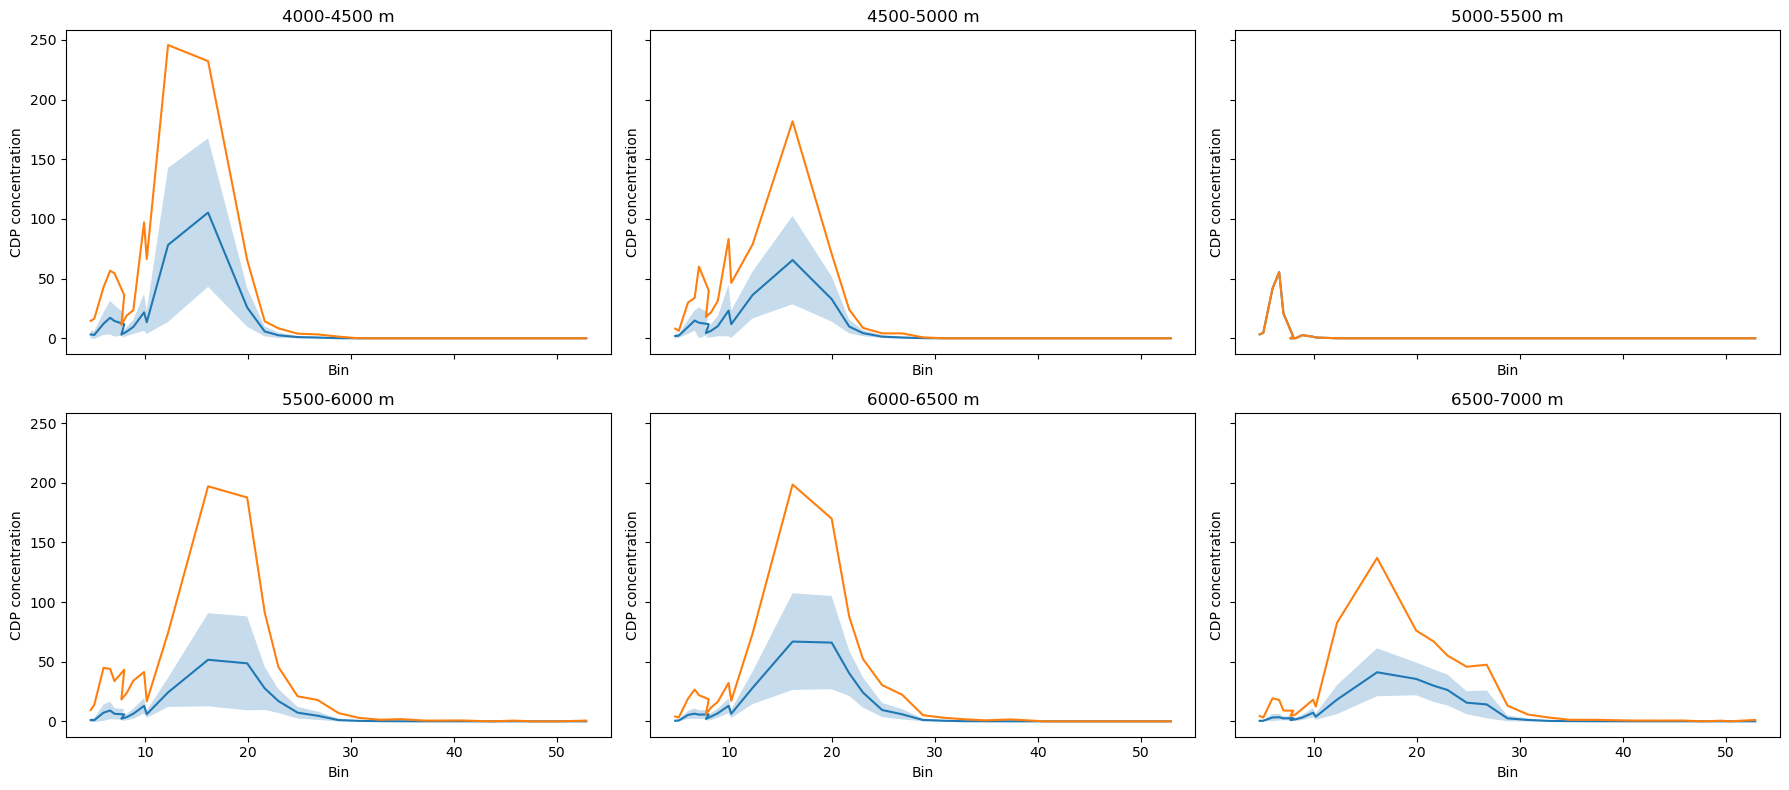

In [ ]:
## also plot the current distributions
DIS, NMAX = 0.25, 500.e6
k = np.arange(24)
xi = 26. - (k + 1.)                                   # channel radius (µm)
D_gauss = 2 * xi * 1e-6                               # channel diameter (m)
dD = 2e-6                                             # channel width in diameter (m)
conv = 1e-12
mu = 2.5                                              # cloud liquid shape parameter (Table A1)


altitude_keys = list(alt_slice.keys())
altitude_keys = altitude_keys[5:11]  # only plot the 5th to 10th altitude bins

n = len(altitude_keys)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4 * nrows),
    sharex=True,
    sharey=True)

axes = axes.flatten()

for i, key in enumerate(altitude_keys):

    data = alt_slice[key]
    mean = data.mean(dim='time')
    sd = data.std(dim='time')
    maximum = data.max(dim='time')
    median = data.median(dim='time')
    x = masked_data['bin'].values
    m = mean.values
    s = sd.values

    axes[i].plot(x, m, label='Mean')
    axes[i].fill_between(x, m - s, m + s, alpha=0.25, label='± 1 SD')
    axes[i].plot(x, maximum.values, label='Max')

    '''

    ## now doing bits for plotting the other distributions
    n_min_alt, n_max_alt = key.split('-')
    indices = np.where((alt >= int(n_min_alt)) & (alt < int(n_max_alt)))[0]
    start_idx = indices[0]
    end_idx = indices[-1]
    db_slice = db[start_idx:end_idx + 1]
    dbar = db_slice.mean()

    stdv = DIS * dbar / 2.
    yi = NMAX * np.exp(-((xi - dbar / 2.) / stdv) ** 2 / 2.)   # m^-3 per channel
    n_gauss = yi / dD                                     # size density (m^-3 m^-1)

    # ---------- CASIM gamma PSD, Field et al. (2023) A1 & A2 ----------
    n_x = yi.sum()                                        # same total number as the Gaussian (m^-3)
    lam = (1 + mu) / (dbar * 1e-6)                        # slope (m^-1): mean diameter = dbar
    D = np.linspace(0, 60e-6, 600)                        # diameters (m)
    n0 = n_x * lam ** (1 + mu) / gamma(1 + mu)            # (A2)
    N_D = n0 * D ** mu * np.exp(-lam * D)                 # (A1)


    
    axes[i].plot(D * 1e6, N_D * conv, label=f"CASIM gamma (μ={mu}, mean D={dbar} µm)")
    axes[i].plot(D_gauss * 1e6, n_gauss * conv, "o-", label="Gaussian scheme")
    '''
    axes[i].set_title(f'{key} m')
    axes[i].set_xlabel('Bin')
    axes[i].set_ylabel('CDP concentration')

# Remove unused subplots
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### LWC distributions

Text(0, 0.5, 'Frequency')

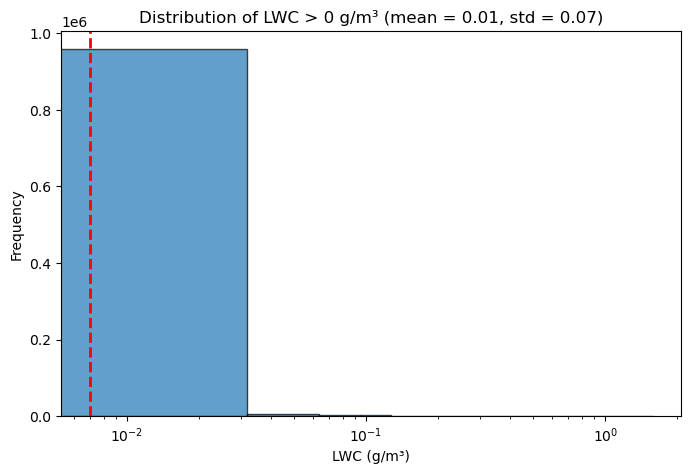

In [ ]:
lwc_threshold = 0
lwc_data = combined_dic['mean_LWC_64hz']['data']
lwc_data_masked = lwc_data.where(lwc_data >= lwc_threshold)
data = lwc_data_masked.values.flatten()
data = data[~np.isnan(data)]

mean = np.mean(data)
sd = np.std(data)

plt.figure(figsize=(8, 5))

plt.hist(data, bins=50, edgecolor='black', alpha=0.7)

plt.axvline(mean, color='red', linestyle='--',
            linewidth=2, label=f'Mean = {mean:.2f}')
plt.xscale('log')

plt.title(f'Distribution of LWC > {lwc_threshold} g/m³ (mean = {mean:.2f}, std = {sd:.2f})')
plt.xlabel('LWC (g/m³)')
plt.ylabel('Frequency')

In [ ]:
min_lwc = np.floor(lwc_data_masked.min(skipna=True).compute().item())# / 100)# * 100
max_lwc = np.ceil(lwc_data_masked.max(skipna=True).compute().item())# / 100)# * 100

bin_edges = np.arange(min_lwc, max_lwc + 0.025, 0.25)

In [ ]:
## slice up the distributions according to lwc bins
## !! also need above 50cc conc (per second) to be included in the distribution
## this is not accounting for time!!
cdp_conc_data = combined_dic['cdp_conc']['data']
cdp_psd_data = combined_dic['cdp_psd']['data']

min_cdp_conc = 100  # minimum concentration threshold

if 'Time' in lwc_data_masked.dims:
    lwc_data_masked = lwc_data_masked.rename({'Time': 'time'})

# Sort timestamps (required for nearest reindexing)
lwc_data_masked = lwc_data_masked.sortby('time')

# lwc is 64hz, cdp is lower, need to interpolate
lwc_cdp = lwc_data_masked.reindex(
    time=cdp_psd_data.time,
    method='nearest',
    tolerance=np.timedelta64(1, 's'))

lwc_slice = {}
for i in range(len(bin_edges) - 1):
    lower_bound = bin_edges[i]
    upper_bound = bin_edges[i + 1]

    # Select observations within altitude range
    lwc_mask = (
        (lwc_cdp >= lower_bound) &
        (lwc_cdp < upper_bound)
    )

    # Select observations where concentration > 50
    cdp_mask = cdp_conc_data > min_cdp_conc

    # Combine masks
    valid = lwc_mask & cdp_mask

    # Apply combined mask to PSD
    masked_data = cdp_psd_data.where(valid)

    # Store
    lwc_slice[f"{lower_bound}-{upper_bound}"] = masked_data



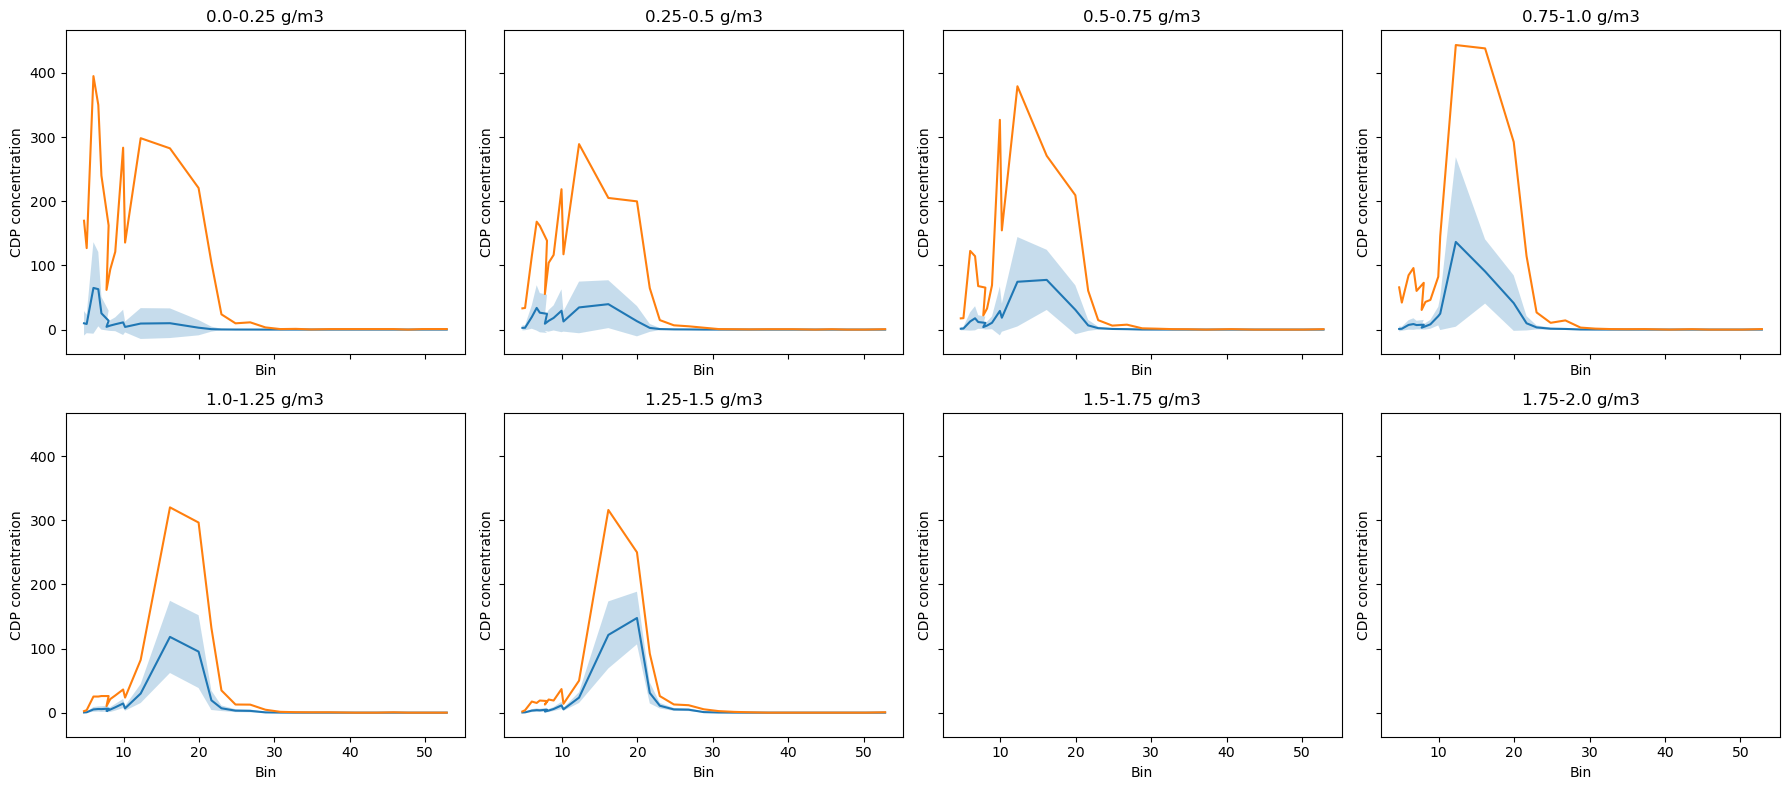

In [ ]:
lwc_keys = list(lwc_slice.keys())

n = len(lwc_keys)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4 * nrows),
    sharex=True,
    sharey=True)

axes = axes.flatten()

for i, key in enumerate(lwc_keys):

    data = lwc_slice[key]
    mean = data.mean(dim='time')
    sd = data.std(dim='time')
    maximum = data.max(dim='time')
    median = data.median(dim='time')
    x = masked_data['bin'].values
    m = mean.values
    s = sd.values

    axes[i].plot(x, m, label='Mean')
    axes[i].fill_between(x, m - s, m + s, alpha=0.25, label='± 1 SD')
    axes[i].plot(x, maximum.values, label='Max')

    axes[i].set_title(f'{key} g/m3')
    axes[i].set_xlabel('Bin')
    axes[i].set_ylabel('CDP concentration')

# Remove unused subplots
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### total conc distributions

Text(0.5, 1.0, 'Distribution of CDP concentration > 0 cm$^-3$')

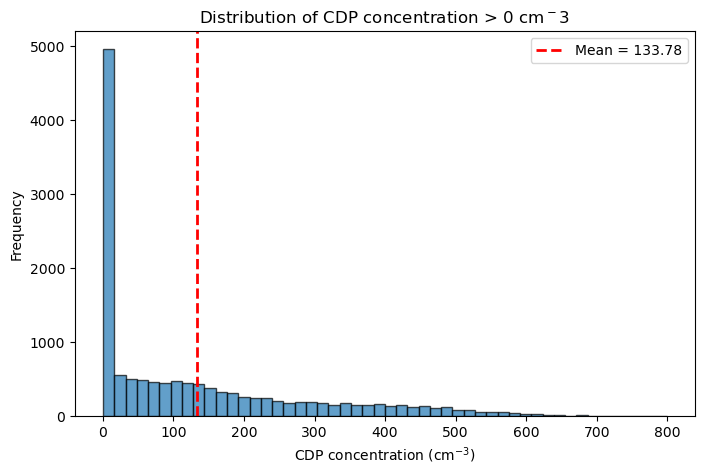

In [ ]:
conc_threshold = 0
conc_data_raw = combined_dic['cdp_conc']['data']
conc_data = conc_data_raw.values.flatten()
conc_data = conc_data[~np.isnan(conc_data)]
conc_data_filtered = conc_data[conc_data > conc_threshold]  # Filter out non-positive values


mean = np.mean(conc_data_filtered)
sd = np.std(conc_data_filtered)

plt.figure(figsize=(8, 5))

plt.hist(conc_data_filtered, bins=50, edgecolor='black', alpha=0.7)

plt.axvline(mean, color='red', linestyle='--',
            linewidth=2, label=f'Mean = {mean:.2f}')

plt.xlabel('CDP concentration (cm$^{-3}$)')
plt.ylabel('Frequency')
plt.legend()
plt.title(f'Distribution of CDP concentration > {conc_threshold} cm$^{-3}$')

In [ ]:
min_conc = np.floor(conc_data_filtered.min())# / 100)# * 100
max_conc = np.ceil(conc_data_filtered.max())# / 100)# * 100

bin_edges = np.arange(min_conc, max_conc + 100, 100)
#print(min_conc, max_conc)
bin_edges

array([  0., 100., 200., 300., 400., 500., 600., 700., 800.])

In [ ]:
## slice up the distributions according to lwc bins
## !! also need above 50cc conc (per second) to be included in the distribution
## this is not accounting for time!!
cdp_conc_data = combined_dic['cdp_conc']['data']
cdp_psd_data = combined_dic['cdp_psd']['data']

#min_cdp_conc = 100  # minimum concentration threshold

conc_slice = {}
for i in range(len(bin_edges) - 1):
    lower_bound = bin_edges[i]
    upper_bound = bin_edges[i + 1]

    # Select observations within altitude range
    conc_mask = (
        (conc_data_raw >= lower_bound) &
        (conc_data_raw < upper_bound)
    )

    # Select observations where concentration > 50
    #cdp_mask = cdp_conc_data > min_cdp_conc

    # Combine masks
    #valid = conc_mask #& cdp_mask

    # Apply combined mask to PSD
    masked_data = cdp_psd_data.where(conc_mask)

    # Store
    conc_slice[f"{lower_bound}-{upper_bound}"] = masked_data



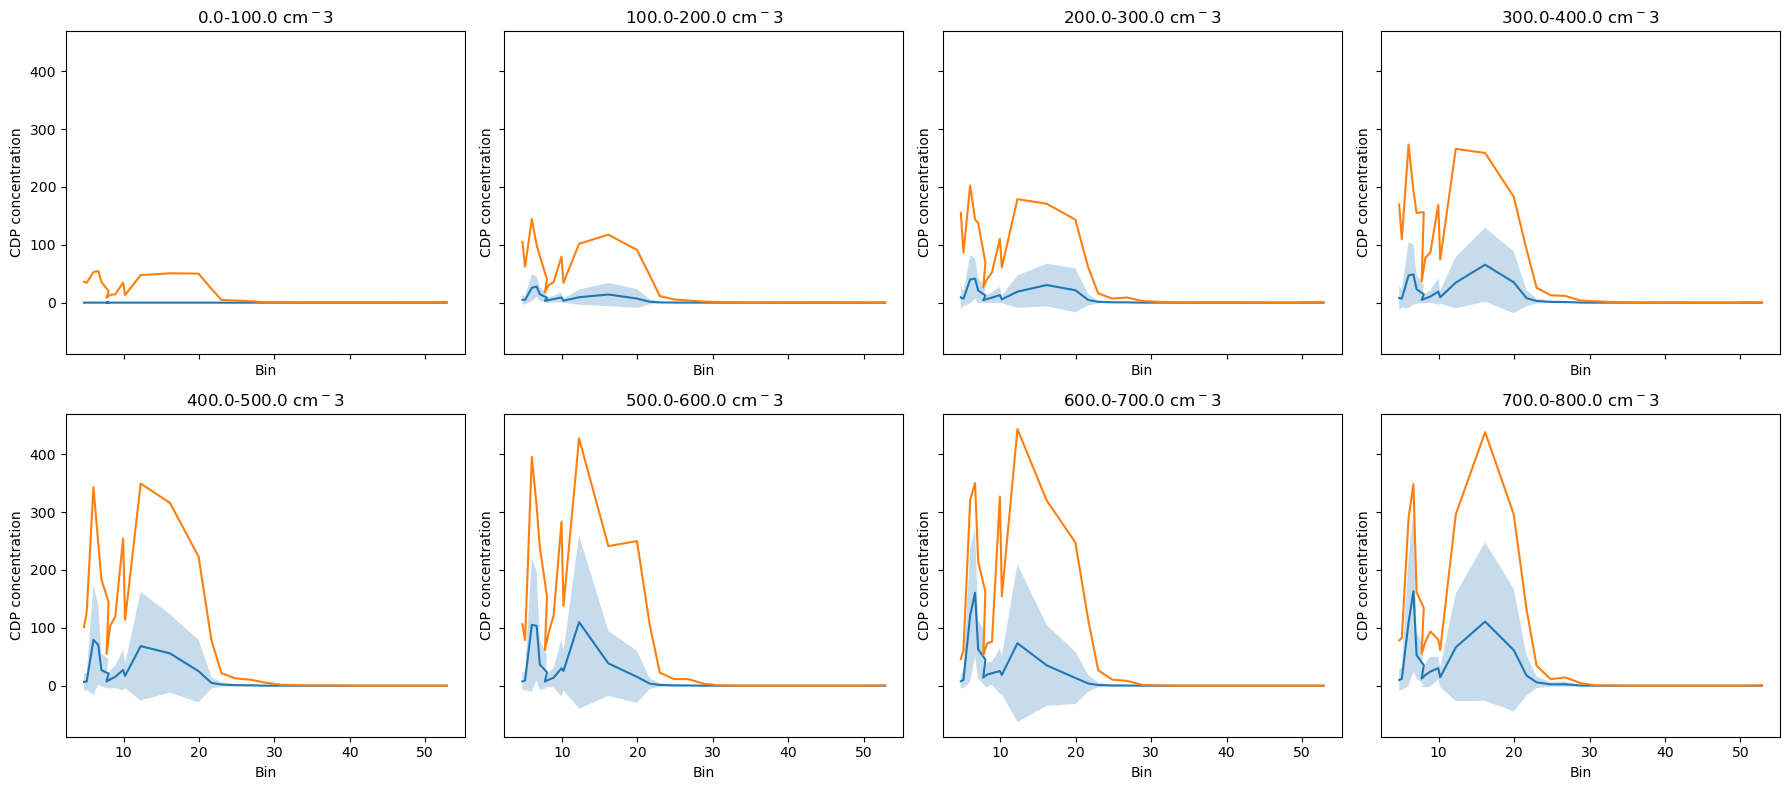

In [ ]:
conc_keys = list(conc_slice.keys())

n = len(conc_keys)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4 * nrows),
    sharex=True,
    sharey=True)

axes = axes.flatten()

for i, key in enumerate(conc_keys):

    data = conc_slice[key]
    mean = data.mean(dim='time')
    sd = data.std(dim='time')
    maximum = data.max(dim='time')
    median = data.median(dim='time')
    x = masked_data['bin'].values
    m = mean.values
    s = sd.values

    axes[i].plot(x, m, label='Mean')
    axes[i].fill_between(x, m - s, m + s, alpha=0.25, label='± 1 SD')
    axes[i].plot(x, maximum.values, label='Max')

    axes[i].set_title(f'{key} cm$^{-3}$')
    axes[i].set_xlabel('Bin')
    axes[i].set_ylabel('CDP concentration')

# Remove unused subplots
for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# add CASIM to model

In [2]:
# make profiles 
namelist_file = "/home/users/esree/simple-graupel-model/model_development/namelists/namelist_blyth_latham_thermal_test.txt"

with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

diam = namelist['diam']
#numt = int(namelist['runtime'] * 60. / namelist['DELTIM']) ### number of simulation time steps (s)
numt = int(200 * 60. / namelist['DELTIM']) ### number of simulation time steps (s)
numt_0 = numt + 1 # including initial time step (t=0)
MAX1 = len(diam)   # number of particle size categories

thtop1 = np.zeros(numt_0)                          # top alt of thermal 1
thbase1 = np.zeros(numt_0)                         # bottom alt of thermal 1
thtop2 = np.zeros(numt_0)                          # top alt of thermal 2
thbase2 = np.zeros(numt_0)                         # bottom alt of thermal 2
cldtop = np.zeros(numt_0)                          # top of cloud top debis
downbase = np.zeros(numt_0)                        # bottom of cloud top debris
thermodynamic_flag = np.zeros(numt_0)              # flag to indicate if thermodynamic conditions in each section

# the whole environment is initialised with empty arrays defined by MAX values
lw = np.zeros(namelist['MAX2'])                              # LWC (at all heights)
db = np.zeros(namelist['MAX2'])                              # dbar ??
vv = np.zeros(namelist['MAX2'])                              # vertical velocity
alt = np.zeros(namelist['MAX2'])                             # altitude (m?)
ps = np.zeros(namelist['MAX2'])                              # pressure (mb?)
tr = np.zeros(namelist['MAX2'])                              # temperature (Kelvin)
conc = np.zeros(MAX1)                            # concentration of particles in each size category

# 2c. define cloud properties: pressure / temperature / depth /vertical velocity profile - - - - - - - - - - - - - - - - - - - - - - - - - - - -
zbase = ptz(namelist['pbase']) # height of cloud base (m)
#print(f"cloud base: p = {namelist['pbase']:5.1f} mb, T = {namelist['tbase']:4.1f} C, "f"z = {zbase / 1000.:3.1f} km", file=sys.stderr)
cdepth = namelist['CTOP'] - zbase / 1000. # depth of cloud (km)

# vertical velocity change with alt -> slope and intercept of (linear) vertical velocity profile
slope = (namelist['maxup'] - namelist['wbase']) / (namelist['zmax'] - zbase / 1000.)
intcpt = namelist['wbase'] - slope * zbase / 1000.

# 3. set up environmental profile
# build environment profile - - - - - - - - - - - - - - - - - - - - - - - - - - - -
for ii in range(namelist['MAX2']):
    # whole column properties
    alt[ii] = 10. * ii # each level seperated by 10 m
    ps[ii] = ztp(alt[ii]) # pressure
    at_, alwc_ = trev(namelist['pbase'], namelist['tbase'], ps[ii]) # temp + LWC
    lw[ii] = alwc_ * 1.0e-3 # lwc through column
    tr[ii] = at_ + 273.15 # temp through column
    db[ii] = namelist['DBAR'] + ii / 125. # mean cloud drop diameter (not sure why / 125.)

    # environmental updraft
    # vv = vertical velocity defined at each height
    if alt[ii] < zbase:
        # below cloud
        vv[ii] = 1.
    elif alt[ii] / 1000. <= namelist['zmax']:
        # in cloud + alt < max updraft alt
        # increasing updraft to zmax
        vv[ii] = slope * alt[ii] / 1000. + intcpt
    else:
        # in cloud + alt >= zmax
        # decreasing updraft above this
        vv[ii] = (namelist['maxup'] / ((namelist['CTOP'] + 2.) - namelist['zmax'])) * ((namelist['CTOP'] + 2.) - alt[ii] / 1000.0)
        
        #vv[ii] = (namelist['maxup'] / (namelist['CTOP'] - namelist['zmax'])) * ((namelist['CTOP']) - alt[ii] / 1000.0)
        #vv[ii] = namelist['maxup'] - (alt[ii] / 1000.0 - namelist['zmax']) * 1.75 # alike to graupel_thermals_ezri.c



In [ ]:
#### current set up 
# make up some numbers
pos = 600 # 6000m alt

rad = .5 * 1.0e-3 # in m
dmm = rad * 2.0e3
GRAV = 9.81 # gravity
RD = 287.05 # gas constant for dry air (J/kg/K)
temp = tr[pos] - 1.
pres = ps[pos] * 100.
DIS = 0.25 # dispersion 

rhoa = pres / (RD * temp)
rhog = 900. # initial ice density (kg m^-3)
cd = drag(rad, rhog, rhoa)
# initial mass
mass = 4. * np.pi * rad ** 3 * rhog / 3.
ts = 268.15
vt = 8. * rad * rhog * GRAV / (3. * rhoa * cd)
vt = vt ** 0.5

yi_list = []
xi_list = []

delmr = 0.
if dmm > 0.30:
    # droplet spectrum -- Gaussian distribution matched to LWC
    stdv = DIS * namelist['DBAR'] / 2.
    sumkap = 0.
    sumrh = 0.
    sumy = 0.
    if ts < 273.15:
        mom = mass * vt * 1.0e5
        beta = 0.738
        # the cloud is represented by a Gaussian distribution of droplet sizes, with mean dbar and std dev stdv
        # Start: loop through 24 bins of droplet spectrum + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + +                
        for k in range(24):
            # 6.1 Collection kernel calculation - for each channel * * * * * * * * * * * * * * * * * * * * * * * * * *
            xi = (26. - (k + 1.)) * 1.0e-6 # this is radius (m)
            size_mu = xi * 1.0e6 #(um)
            hxa = (xi * 1.0e6 - namelist['DBAR'] / 2.) / stdv
            hxa = hxa ** 2 / 2.
            yi = 500.e6 * math.exp(-hxa) # concentration of droplets in bin k (m^-3)
            sumy = yi + sumy
            yi_list.append(yi/1e6)
            xi_list.append(xi*1e6*2)
            # collection kernel - formulae derived from Beard and Grover (1974) relationships
            # ^ how effectively the graupel collects drops
            
            print(f'K: {k}, xi: {xi* 1.0e6}')
            
            if k == 23: # smallest droplets
                kappa = 1.09 * 1.0e-6 * mom ** beta
            if k == 22:
                kappa = 3.56 * 1.0e-6 * mom ** beta
            if k == 21:
                kappa = 5.41 * 1.0e-6 * mom ** beta
            if k == 20:
                kappa = 6.80 * 1.0e-6 * mom ** beta
            if k == 19:
                kappa = 7.75 * 1.0e-6 * mom ** beta
            if k == 18:
                kappa = 8.37 * 1.0e-6 * mom ** beta
            if k == 17:
                kappa = 8.80 * 1.0e-6 * mom ** beta
            if k == 16:
                kappa = 9.13 * 1.0e-6 * mom ** beta
            if k == 15:
                kappa = 9.38 * 1.0e-6 * mom ** beta
            if k == 14:
                kappa = 9.58 * 1.0e-6 * mom ** beta
            if k == 13:
                kappa = 9.75 * 1.0e-6 * mom ** beta
            if k == 12:
                kappa = 9.87 * 1.0e-6 * mom ** beta
            if k == 11:
                kappa = 9.97 * 1.0e-6 * mom ** beta
            if k == 10:
                kappa = 10.07 * 1.0e-6 * mom ** beta
            if k == 9:
                kappa = 10.17 * 1.0e-6 * mom ** beta
            if k == 8:
                kappa = 10.22 * 1.0e-6 * mom ** beta
            if k == 7:
                kappa = 10.30 * 1.0e-6 * mom ** beta
            if k == 6:
                kappa = 10.37 * 1.0e-6 * mom ** beta
            if k <= 5: # biggest droplets
                kappa = 10.45 * 1.0e-6 * mom ** beta
            sumkap = sumkap + kappa * yi # weight collection kernel by droplet concentration
        

            

K: 0, xi: 24.999999999999996
K: 1, xi: 24.0
K: 2, xi: 23.0
K: 3, xi: 22.0
K: 4, xi: 21.0
K: 5, xi: 20.0
K: 6, xi: 18.999999999999996
K: 7, xi: 18.0
K: 8, xi: 17.0
K: 9, xi: 16.0
K: 10, xi: 14.999999999999998
K: 11, xi: 14.0
K: 12, xi: 13.0
K: 13, xi: 12.0
K: 14, xi: 11.0
K: 15, xi: 10.0
K: 16, xi: 9.0
K: 17, xi: 8.0
K: 18, xi: 7.0
K: 19, xi: 6.0
K: 20, xi: 5.0
K: 21, xi: 4.0
K: 22, xi: 3.0
K: 23, xi: 2.0


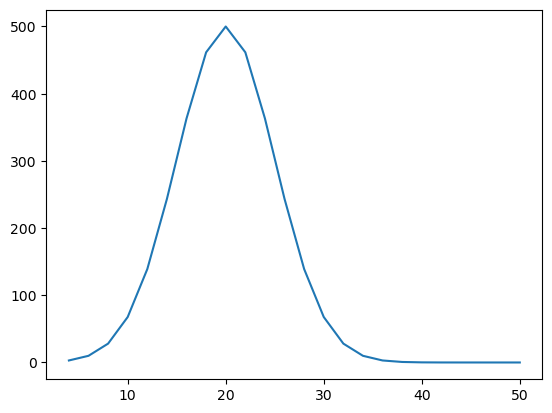

In [43]:
plt.plot(xi_list, yi_list)

In [ ]:
#### current set up 
# make up some numbers
pos = 600 # 6000m alt

rad = .5 * 1.0e-3 # in m
dmm = rad * 2.0e3
GRAV = 9.81 # gravity
RD = 287.05 # gas constant for dry air (J/kg/K)
temp = tr[pos] - 1.
pres = ps[pos] * 100.
DIS = 0.25 # dispersion 

rhoa = pres / (RD * temp)
rhog = 900. # initial ice density (kg m^-3)
cd = drag(rad, rhog, rhoa)
# initial mass
mass = 4. * np.pi * rad ** 3 * rhog / 3.
ts = 268.15
vt = 8. * rad * rhog * GRAV / (3. * rhoa * cd)
vt = vt ** 0.5


hydroparameters = {'liquid': {'mu':2.5,'c':522,'d':3},
                   'cloud': {'mu':2.5,'c':522,'d':3},
                   'rain':{'mu':2.5,'c':522,'d':3},
                   'ice':{'mu':2.5,'c':np.pi*200/6,'d':3},
                   'snow':{'mu':2,'c':0.026,'d':2},
                   'graupel':{'mu':2.5,'c':np.pi*500/6,'d':3}}

lwc = lw[pos] * namelist['RATTH']       # kg m^-3
mu = 2.5
n_cloud_drops = 100e6                   # m^-3


edges = 10**np.linspace(-7, -4, 50)     # m, 0.1 -> 100 µm. 50 bins, log-spaced
lower, upper = edges[:-1], edges[1:]
mid_geom  = np.sqrt(lower * upper)       # geometric midpoint- diameter (m) (the midpoint on a log axis)
radius_mu_list = 0.5 * mid_geom * 1e6       # bin radius (µm)

# safty check to avoid division by zero
if lwc > 0 and n_cloud_drops > 0:
    lam = calc_lambda(lwc, n_cloud_drops, 'cloud')
    yi_all = partial_integral_gamma(n_cloud_drops, mu, lam, lower, upper)
else:
    yi_all = np.zeros(len(lower))

delmr = 0.
if dmm > 0.30:
    # droplet spectrum -- Gaussian distribution matched to LWC
    sumkap = 0.
    sumy = 0.
    if ts < 273.15:
        mom = mass * vt * 1.0e5
        beta = 0.738
        mom_beta = mom ** beta
        # the cloud is represented by a Gaussian distribution of droplet sizes, with mean dbar and std dev stdv
        # Start: loop through 24 bins of droplet spectrum + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + + +                
        for i in range(len(lower)):
            # 6.1 Collection kernel calculation - for each channel * * * * * * * * * * * * * * * * * * * * * * * * * *            
            radius_mu = radius_mu_list[i]
            yi = yi_all[i]  
            sumy = yi + sumy # cumulative sum of droplet concentration - should roughly be n_cloud_drops
            # collection kernel - formulae derived from Beard and Grover (1974) relationships
            # v how effectively the graupel collects drops
                        
            if radius_mu <= 2.0:
                kappa = 1.09 * 1.0e-6 * mom_beta
            elif radius_mu <= 3.0:
                kappa = 3.56 * 1.0e-6 * mom_beta
            elif radius_mu <= 4.0:
                kappa = 5.41 * 1.0e-6 * mom_beta
            elif radius_mu <= 5.0:
                kappa = 6.80 * 1.0e-6 * mom_beta
            elif radius_mu <= 6.0:
                kappa = 7.75 * 1.0e-6 * mom_beta
            elif radius_mu <= 7.0:
                kappa = 8.37 * 1.0e-6 * mom_beta
            elif radius_mu <= 8.0:
                kappa = 8.80 * 1.0e-6 * mom_beta
            elif radius_mu <= 9.0:
                kappa = 9.13 * 1.0e-6 * mom_beta
            elif radius_mu <= 10.0:
                kappa = 9.38 * 1.0e-6 * mom_beta
            elif radius_mu <= 11.0:
                kappa = 9.58 * 1.0e-6 * mom_beta
            elif radius_mu <= 12.0:
                kappa = 9.75 * 1.0e-6 * mom_beta
            elif radius_mu <= 13.0:
                kappa = 9.87 * 1.0e-6 * mom_beta
            elif radius_mu <= 14.0:
                kappa = 9.97 * 1.0e-6 * mom_beta
            elif radius_mu <= 15.0:
                kappa = 10.07 * 1.0e-6 * mom_beta
            elif radius_mu <= 16.0:
                kappa = 10.17 * 1.0e-6 * mom_beta
            elif radius_mu <= 17.0:
                kappa = 10.22 * 1.0e-6 * mom_beta
            elif radius_mu <= 18.0:
                kappa = 10.30 * 1.0e-6 * mom_beta
            elif radius_mu <= 19.0:
                kappa = 10.37 * 1.0e-6 * mom_beta
            #if radius_mu >= 20.0:
            else:
                kappa = 10.45 * 1.0e-6 * mom_beta
            sumkap = sumkap + kappa * yi # weight collection kernel by droplet concentration
            
'''
## another alternative is an interpolation of values:
r_tab = np.arange(2, 21) # 2, 3, ... 20 µm
k_tab = np.array([1.09, 3.56, 5.41, 6.80, 7.75, 8.37, 8.80, 9.13, 9.38, 9.58,
                  9.75, 9.87, 9.97, 10.07, 10.17, 10.22, 10.30, 10.37, 10.45])
kappa_coef = np.interp(radius_mu_list, r_tab, k_tab)
'''
radius_mu_list

array([ 0.05365155,  0.06177414,  0.07112647,  0.08189469,  0.09429316,
        0.10856872,  0.12500552,  0.14393078,  0.16572124,  0.19081067,
        0.21969853,  0.25295987,  0.29125684,  0.33535178,  0.3861225 ,
        0.44457967,  0.51188698,  0.58938432,  0.67861439,  0.78135349,
        0.89964681,  1.0358492 ,  1.192672  ,  1.37323706,  1.58113883,
        1.82051597,  2.09613372,  2.41347872,  2.77886829,  3.19957617,
        3.68397728,  4.24171449,  4.88389055,  5.62328911,  6.47462921,
        7.45485829,  8.58348953,  9.88299036, 11.37922963, 13.10199264,
       15.08557405, 17.36946056, 19.99911698, 23.02689128, 26.51305668,
       30.52701148, 35.14866058, 40.47000608, 46.59697881])

In [64]:
print(len(mid_geom*1e6))

print(yi_all)
print(yi)
sumy / n_cloud_drops

49
[1.95732917e+00 3.19833191e+00 5.22429699e+00 8.53008451e+00
 1.39210786e+01 2.27067688e+01 3.70138960e+01 6.02920358e+01
 9.81280574e+01 1.59554765e+02 2.59147255e+02 4.20369388e+02
 6.80894122e+02 1.10102167e+03 1.77692502e+03 2.86135478e+03
 4.59575430e+03 7.35961803e+03 1.17455254e+04 1.86717148e+04
 2.95483032e+04 4.65179400e+04 7.27957641e+04 1.13134725e+05
 1.74436337e+05 2.66506541e+05 4.02910560e+05 6.01795283e+05
 8.86407983e+05 1.28483981e+06 1.82828053e+06 2.54686002e+06
 3.46213316e+06 4.57570580e+06 5.85473625e+06 7.21731002e+06
 8.52373578e+06 9.58244847e+06 1.01789892e+07 1.01304370e+07
 9.35439794e+06 7.92525235e+06 6.08209314e+06 4.16634739e+06
 2.50502553e+06 1.29675259e+06 5.65352357e+05 2.02420336e+05
 5.78298889e+04]
57829.888943550235


np.float64(0.9998488386679171)

In [5]:
for k in range(24):
    xi = ((26. - (k + 1.)) * 1.0e-6)
    bin_min = xi - (0.5e-6)
    bin_max = xi + (0.5e-6)
    print(f'Bin {k}: {bin_min * 1.0e6} to {bin_max * 1.0e6}, diameter = {xi*2 * 1.0e6} µm')

Bin 0: 24.5 to 25.499999999999996, diameter = 49.99999999999999 µm
Bin 1: 23.500000000000004 to 24.5, diameter = 48.0 µm
Bin 2: 22.5 to 23.5, diameter = 46.0 µm
Bin 3: 21.5 to 22.499999999999996, diameter = 44.0 µm
Bin 4: 20.5 to 21.499999999999996, diameter = 42.0 µm
Bin 5: 19.5 to 20.499999999999996, diameter = 40.0 µm
Bin 6: 18.5 to 19.499999999999996, diameter = 37.99999999999999 µm
Bin 7: 17.500000000000004 to 18.5, diameter = 36.0 µm
Bin 8: 16.5 to 17.5, diameter = 34.0 µm
Bin 9: 15.5 to 16.499999999999996, diameter = 32.0 µm
Bin 10: 14.499999999999998 to 15.499999999999996, diameter = 29.999999999999996 µm
Bin 11: 13.5 to 14.5, diameter = 28.0 µm
Bin 12: 12.499999999999998 to 13.5, diameter = 26.0 µm
Bin 13: 11.5 to 12.5, diameter = 24.0 µm
Bin 14: 10.5 to 11.5, diameter = 22.0 µm
Bin 15: 9.499999999999998 to 10.5, diameter = 20.0 µm
Bin 16: 8.5 to 9.5, diameter = 18.0 µm
Bin 17: 7.499999999999999 to 8.5, diameter = 16.0 µm
Bin 18: 6.5 to 7.5, diameter = 14.0 µm
Bin 19: 5.5 to 6

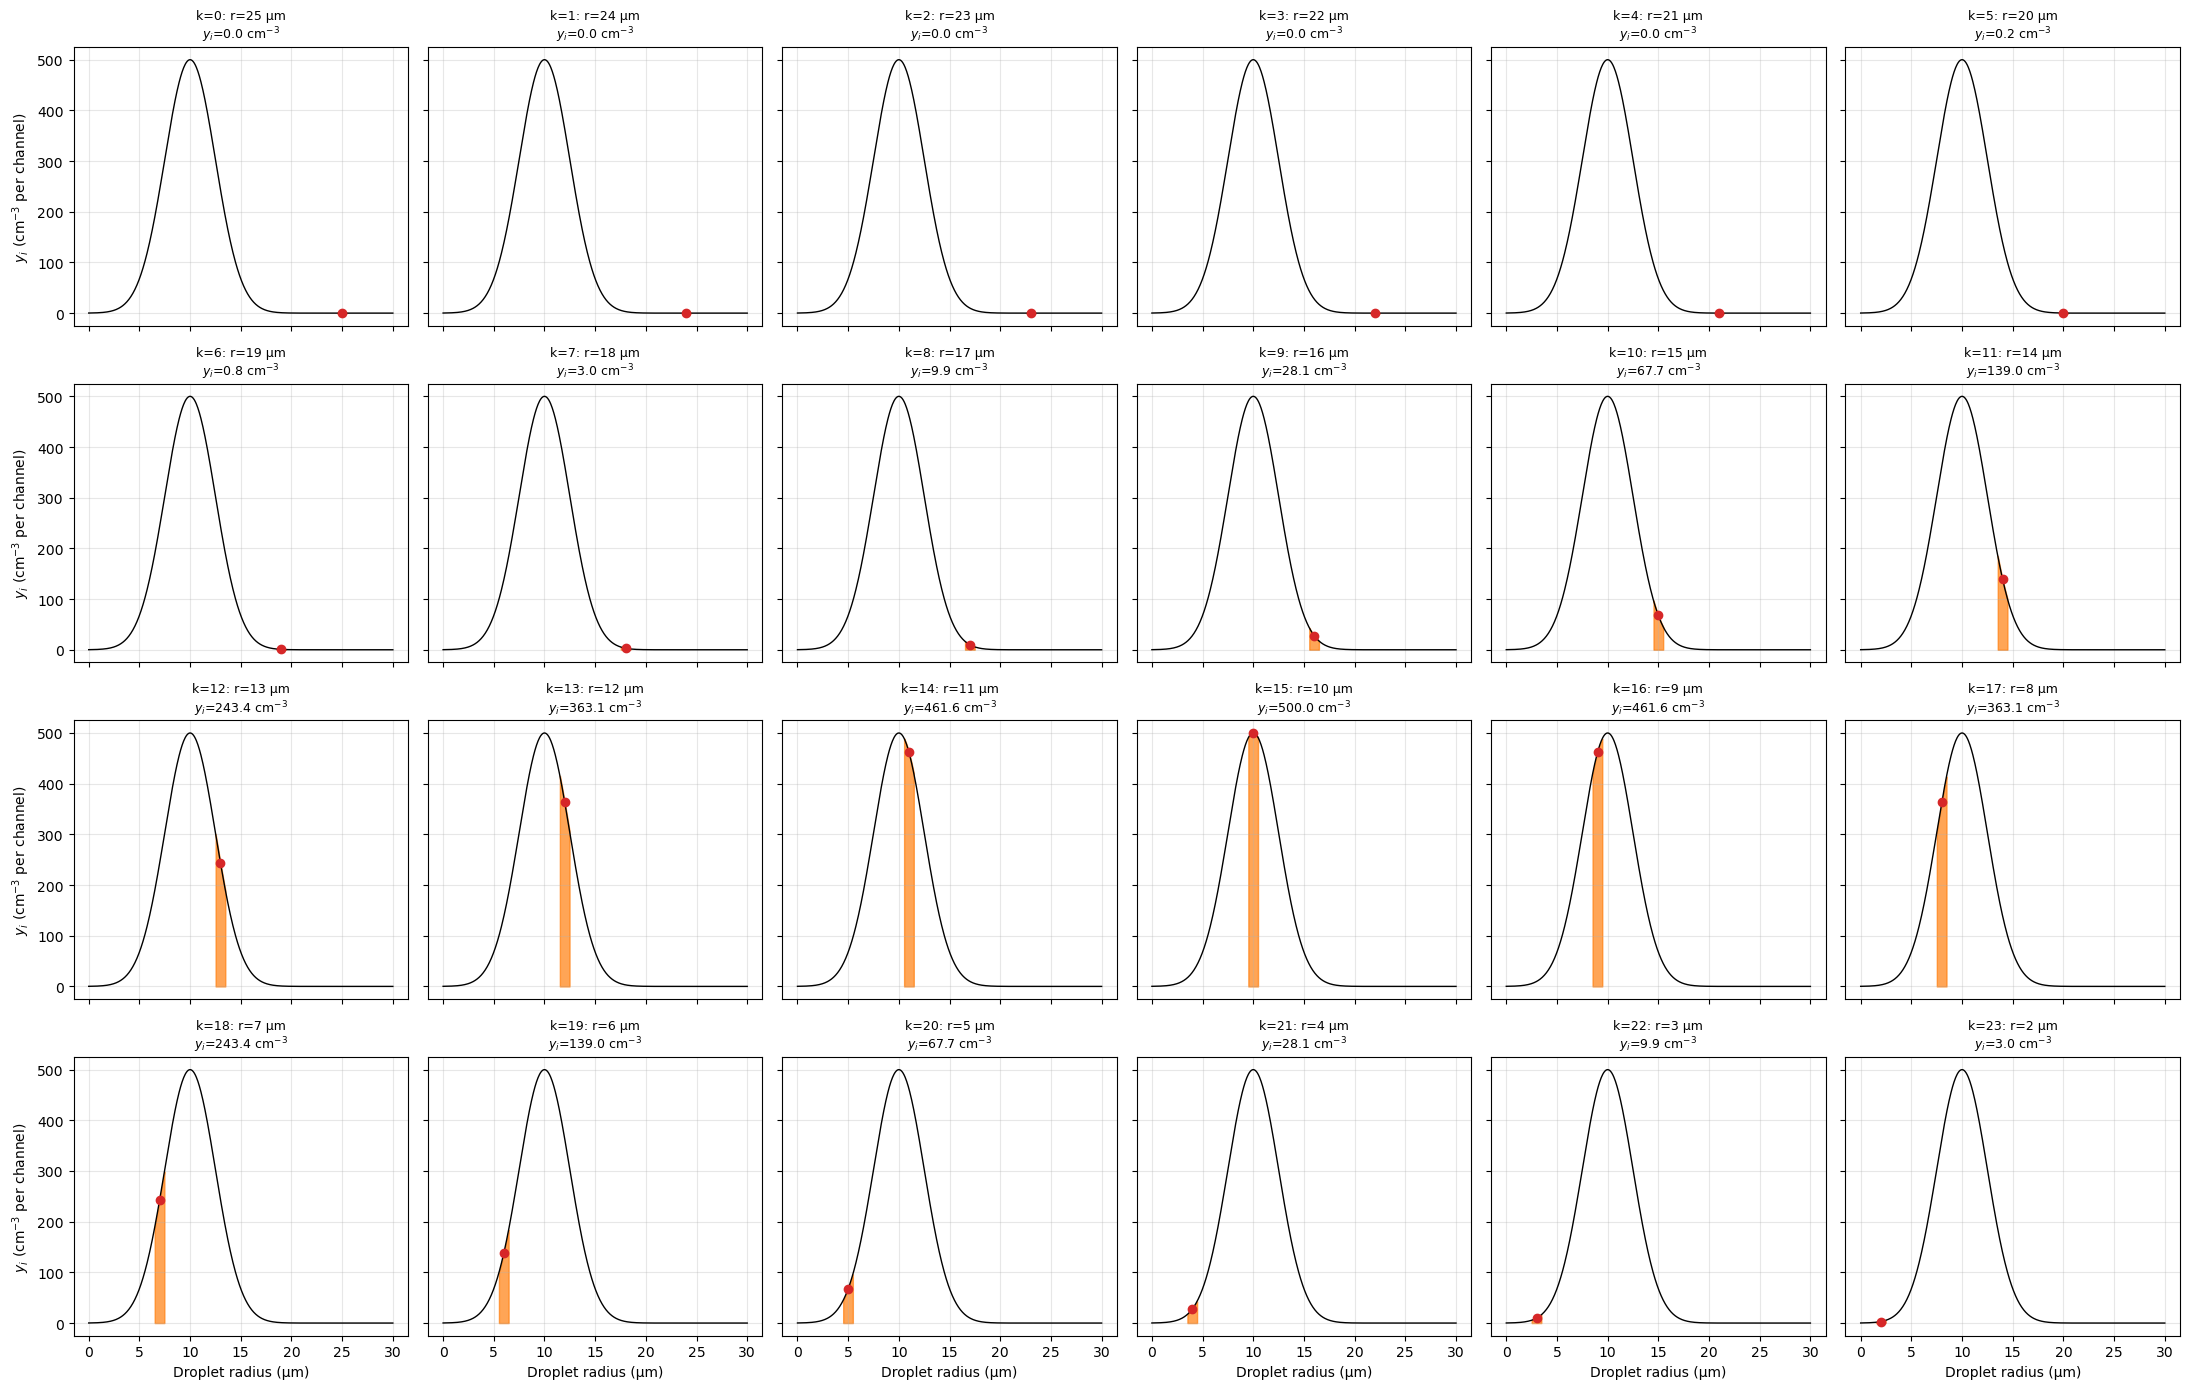

In [6]:
DIS, NMAX, dbar = 0.25, 500.e6, 20
stdv = DIS * dbar / 2.

# the continuous Gaussian that the loop samples (x = radius in µm)
r = np.linspace(0, 30, 600)
curve = NMAX * np.exp(-((r - dbar / 2.) / stdv) ** 2 / 2.)

def plot_channel(k, ax):
    xi = (26. - (k + 1.)) * 1.0e-6               # as in your loop
    r_k = xi * 1.0e6                              # radius (µm)
    hxa = (r_k - dbar / 2.) / stdv
    hxa = hxa ** 2 / 2.
    yi = NMAX * math.exp(-hxa)                    # as in your loop

    ax.plot(r, curve / 1e6, 'k', lw=1)
    sel = (r >= r_k - 0.5) & (r <= r_k + 0.5)     # channel width is 1 µm in radius
    ax.fill_between(r[sel], curve[sel] / 1e6, color='C1', alpha=0.7)
    ax.plot(r_k, yi / 1e6, 'o', color='C3')       # the value the loop uses
    ax.set_title(f"k={k}: r={r_k:.0f} µm\n$y_i$={yi/1e6:.1f} cm$^{{-3}}$", fontsize=9)
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(4, 6, figsize=(22, 14), sharex=True, sharey=True)
for k, ax in enumerate(axes.flat):
    plot_channel(k, ax)
for ax in axes[-1]:
    ax.set_xlabel('Droplet radius (µm)')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$y_i$ (cm$^{-3}$ per channel)')
plt.tight_layout()
plt.show()

In [7]:
# how does this look if CASIM?
### Function for model gamma function in (m-3 m-1)
# x = diameter, n = number conc, mu = mu, lambda = lambda (needs calculating)
def model_gamma_pdf(x,n,mu,lamda):
    n0 = (n) * (lamda**(1+mu)) / (gamma(1+mu)) # directly pulled from field paper - (A2)
    N = n0 * (x**mu) * (np.exp(-lamda*x)) 
    return N

### Function for integral over the lower and upper limits of the gamma PDF
def partial_integral_gamma(n,mu,lam,lower,upper):
    lower_inc = gammainc(1+mu,lam*lower)
    upper_inc = gammainc(1+mu,lam*upper)
    return n*(upper_inc-lower_inc)

## Function for calculating lamda from mass and number
## with prescribed model number + mass (+ specify type of hydrometeor), lambda can be calculated - to work out distribution
def calc_lambda(model_mass,model_num,hydro):
    # Read in gamma PDF values (Field et al., 2023, Table 1)
    mu = hydroparameters[hydro]['mu']
    c = hydroparameters[hydro]['c']
    d = hydroparameters[hydro]['d']
    
    gamma_ratio = gamma(1+mu+d) / gamma(1+mu)
    nm_ratio = model_num / model_mass
    if d == 2:
        lam = np.sqrt(c*nm_ratio*gamma_ratio)
    elif d == 3:
        lam = np.cbrt(c*nm_ratio*gamma_ratio)
    else:
        print("Woohoo, something is wrong here for the moment value!")
        lam = np.nan
    return lam

# hydroparameters c and d are the mass-dimension parameters
hydroparameters = {'liquid': {'mu':2.5,'c':522,'d':3},
                   'cloud': {'mu':2.5,'c':522,'d':3},
                   'rain':{'mu':2.5,'c':522,'d':3},
                   'ice':{'mu':2.5,'c':np.pi*200/6,'d':3},
                   'snow':{'mu':2,'c':0.026,'d':2},
                   'graupel':{'mu':2.5,'c':np.pi*500/6,'d':3}}

In [8]:
lwc = lw[pos] * namelist['RATTH'] # say we are in a thermal
lwc

NameError: name 'pos' is not defined

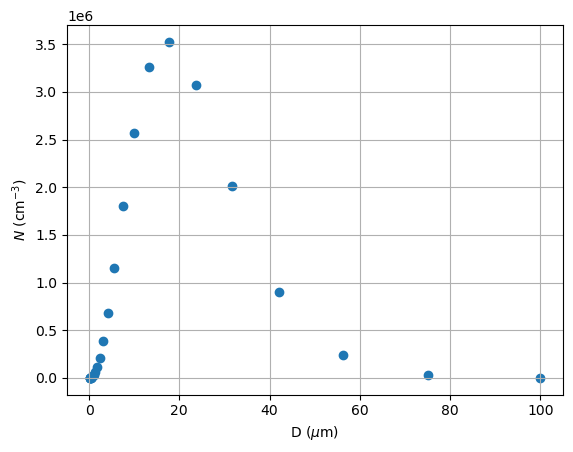

In [15]:
pos = 600 # 6000m alt

lwc = lw[pos] * namelist['RATTH'] # lw is in kg/m3
mu = 2.5            # fixed shape parameter 
n_cloud_drops = 100e6    # fixed number of cloud droplets (m^-3) - to prescribe in the namelist

lam = calc_lambda(lwc, n_cloud_drops, 'cloud') # calculate lambda for the gamma distribution
powers = np.linspace(-7,-4,25)
centre = 10**powers
lower = centre[:-1]
upper = centre[1:]

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax1.set_ylabel('$N$ (cm$^\mathrm{-3}$)')
ax1.set_xlabel('D ($\mu$m)')
ax1.scatter(centre*1e6, model_gamma_pdf(centre,n_cloud_drops,mu,lam)/1e6)

ax1.grid(True)

In [17]:
#width = np.diff(edges)                              # m
#centre = np.sqrt(lower * upper)                     # geometric centre, suits log bins
#plt.step(edges[:-1] * 1e6, yi / width / 1e12, where='post', label='bins')   # cm^-3 µm^-1
#plt.plot(centre * 1e6, yi / width / 1e12, 'o')


yi = np.zeros(len(lower))
for i in range(len(lower)):
    yi[i] = partial_integral_gamma(n_cloud_drops, mu, lam, lower[i], upper[i])   # m^-3 in bin i

# or without the loop (gammainc accepts arrays)
yi = partial_integral_gamma(n_cloud_drops, mu, lam, lower, upper)

print(yi.sum() / n_cloud_drops) 

0.999848838667917


0.999848838667917


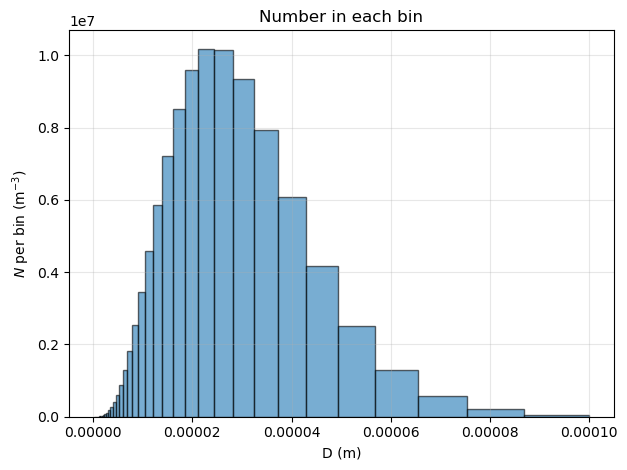

In [47]:
pos = 600  # 6000m alt

lwc = lw[pos] * namelist['RATTH']       # kg m^-3
mu = 2.5
n_cloud_drops = 100e6                   # m^-3
lam = calc_lambda(lwc, n_cloud_drops, 'cloud')

edges = 10**np.linspace(-7, -4, 50)     # m, 0.1 -> 100 µm
lower, upper = edges[:-1], edges[1:]
width = upper - lower                   # m

yi = partial_integral_gamma(n_cloud_drops, mu, lam, lower, upper)   # m^-3 per bin
print(yi.sum() / n_cloud_drops)         # fraction of n captured by the bins

#fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
fig = plt.figure()

ax1 = fig.add_subplot(111)

# left: number in each bin
ax1.bar(lower, yi, width=width, align='edge', edgecolor='k', alpha=0.6)
#ax1.set_xscale('log')
ax1.set_xlabel(r'D (m)')
ax1.set_ylabel(r'$N$ per bin (m$^{-3}$)')
ax1.set_title('Number in each bin')
ax1.grid(True, alpha=0.3)
'''
# right: bins as a density, against the continuous curve
D = np.logspace(-7, -4, 400)            # m
ax2.bar(lower * 1e6, yi / width / 1e12, width=width * 1e6, align='edge', edgecolor='k', alpha=0.6, label='bins')
ax2.plot(D * 1e6, model_gamma_pdf(D, n_cloud_drops, mu, lam) / 1e12, 'k', label='gamma PDF (A1)')
ax2.set_xscale('log')
ax2.set_xlabel(r'D ($\mu$m)')
ax2.set_ylabel(r'$N(D)$ (cm$^{-3}$ $\mu$m$^{-1}$)')
ax2.set_title('Bins as a density')
ax2.legend()
ax2.grid(True, alpha=0.3)
'''
plt.tight_layout()
plt.show()

In [14]:
len(bins*1e6)
bins*1e6
#10**powers

array([1.00000000e-01, 1.33352143e-01, 1.77827941e-01, 2.37137371e-01,
       3.16227766e-01, 4.21696503e-01, 5.62341325e-01, 7.49894209e-01,
       1.00000000e+00, 1.33352143e+00, 1.77827941e+00, 2.37137371e+00,
       3.16227766e+00, 4.21696503e+00, 5.62341325e+00, 7.49894209e+00,
       1.00000000e+01, 1.33352143e+01, 1.77827941e+01, 2.37137371e+01,
       3.16227766e+01, 4.21696503e+01, 5.62341325e+01, 7.49894209e+01,
       1.00000000e+02])

In [13]:
mom = mass * vt * 1.0e5
beta = 0.738

kappa = 10.37 * 1.0e-6 * mom ** beta


In [1]:
import sys
import math
from datetime import datetime
from scipy.special import gammainc, gdtr

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
from scipy.special import gamma



In [2]:
edges = 10**np.linspace(-7, -4, 50)     # m, 0.1 -> 100 µm. 50 bins, log-spaced
lower, upper = edges[:-1], edges[1:]
mid_geom  = np.sqrt(lower * upper)       # geometric midpoint- diameter (m) (the midpoint on a log axis)
radius_mu_list = 0.5 * mid_geom * 1e6       # bin radius (µm)

In [3]:
radius_mu_list

array([ 0.05365155,  0.06177414,  0.07112647,  0.08189469,  0.09429316,
        0.10856872,  0.12500552,  0.14393078,  0.16572124,  0.19081067,
        0.21969853,  0.25295987,  0.29125684,  0.33535178,  0.3861225 ,
        0.44457967,  0.51188698,  0.58938432,  0.67861439,  0.78135349,
        0.89964681,  1.0358492 ,  1.192672  ,  1.37323706,  1.58113883,
        1.82051597,  2.09613372,  2.41347872,  2.77886829,  3.19957617,
        3.68397728,  4.24171449,  4.88389055,  5.62328911,  6.47462921,
        7.45485829,  8.58348953,  9.88299036, 11.37922963, 13.10199264,
       15.08557405, 17.36946056, 19.99911698, 23.02689128, 26.51305668,
       30.52701148, 35.14866058, 40.47000608, 46.59697881])